`[1]`

# Seleção de variáveis — fosfato na área reduzida (AR) de Irecê

Escolhe as variáveis do RF e do GTB de fosfato na área reduzida, juntando ASTER,
geofísica do acervo CPRM (gama e mag) e geologia 1:250 mil. Desafios e decisões
em `docs/desafios_bases_dados.md`.

| Peça | Papel |
|---|---|
| `amostras_AR.py` | amostras no GEE → `src/Dados/maxent/amostras_AR_<area>.csv` + `_grupos.json` |
| este notebook | seleção de variáveis → `models/variaveis_AR_<area>.json` (célula [19]) |
| `exportar_favorabilidade_AR.py` | mapa RF/GTB no GEE com as variáveis escolhidas |

**Por que tanto cuidado.** São 13 ocorrências (11 com geofísica). O buffer de
250 m tem ~218 pixels de 30 m, mas todos caem no mesmo pixel de ~500 m do gama:
são cópias de uma observação. Por isso:
- cada ocorrência entra com o mesmo número de pixels (`N_POR_PONTO`);
- a validação deixa de fora um **grupo de ocorrências vizinhas** e o fundo da
  região dele (folds espaciais), nunca pixels soltos;
- a importância das variáveis é repetida em reamostragens e só fica o que é estável.

**Seções**
1. Dados e exploração
2. Redundância (Spearman no fundo, uma variável por grupo de |r| > `R_MAX`)
3. Validação espacial (folds por grupo de ocorrências)
4. Ablação por grupo: a geofísica ajuda? qual parte?
5. Ranking estável (SHAP fora da amostra em reamostragens)
6. Conferência independente com o P₂O₅ das amostras de rocha
7. Variáveis salvas para o export

In [1]:
# [2]
import json
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.cluster import hierarchy
from scipy.spatial.distance import squareform
from scipy.stats import spearmanr
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.cluster import KMeans
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings('ignore', category=UserWarning)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})

RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'Dados').exists())   # src/
PASTA = RAIZ / 'Dados' / 'maxent'
MODELS = RAIZ / 'modeling' / 'models'
FIGS = MODELS / 'figuras_selecao_AR'
FIGS.mkdir(parents=True, exist_ok=True)

AREA = 'irece_shm'   # amostras_AR.ID_AR: área + sufixo do mosaico ('_shm' = harmonizado; 'irece' = v1)
ARQ = PASTA / f'amostras_AR_{AREA}.csv'
META = json.loads((PASTA / f'amostras_AR_{AREA}_grupos.json').read_text())

# ── parâmetros da análise ───────────────────────────────────────────────────
N_POR_PONTO   = 100     # pixels por ocorrência (o mesmo no exportar_favorabilidade_AR.py)
R_MAX         = 0.85    # |Spearman| acima disso = redundante
N_FOLDS       = 5       # folds: ocorrências vizinhas agrupadas por k-means das coordenadas
BLOCO_KM      = 10      # fundo dividido em blocos de BLOCO_KM km, sorteados entre os folds
N_REP         = 20      # reamostragens do ranking estável
FRAC_REP      = 0.8     # fração das ocorrências em cada reamostragem
TOP_K         = 15       # "no topo" = entre as TOP_K mais importantes
FREQ_MIN      = 0.7     # entra quem fica no topo em ≥ 70% das repetições
SHAP_N        = 300     # amostras explicadas por fold (metade presença, metade fundo)
SHAP_MODELOS  = ['GTB', 'RF']
N_BOOT        = 1000    # bootstrap das ocorrências (intervalo da AUC por ponto)
LIMIAR_P2O5   = 5.0     # % P2O5 "alto" na conferência
FUNDO_MODO    = 'cluster'   # fundo do TREINO: 'aleatorio' (todo) ou 'cluster' (só clusters distantes, [10a])
K_FUNDO       = 10      # k-means: número de clusters do fundo (fixo)
FRAC_MIN_FUNDO = 0.2    # se sobrar menos que isso do fundo, completa pelos clusters mais distantes
# variáveis do agrupamento do fundo (sem litologia). Exigem geofísica: nos conjuntos da área
# toda (sem gama/mag em ~1/3 do fundo) o treino usa o fundo aleatório
VARS_CLUSTER  = ['eU_ppm', 'eTh_ppm', 'U_Th', 'Th_K', 'eU_res', 'MAG_nT', 'mag_res', 'mag_thg',
                 'sultan_r', 'sultan_g', 'sultan_b', 'B10', 'quartz_14_12', 'phosphorite_rbd']
SEED          = 42
rng = np.random.default_rng(SEED)
DPI_FIG = 350

# ordem de preferência para representar um grupo redundante: FEATURES_DL do SHAP da
# R2 (avaliar_maxent [34], dado independente desta escolha), depois gama, mag e o resto
FEATURES_DL = ['quartz_14_12', 'B10', 'ferric_iron_2_1', 'glcm_contrast', 'B09', 'sultan_g',
               'phosphorite_rbd', 'gossan_4_2', 'sultan_r', 'ferric_ox_4_3', 'SAVI', 'B01', 'B3N',
               'carbonate_13_14', 'kaolinite_7_5', 'carbonate_8_6', 'glcm_hom', 'dolomite',
               'sericite_illite_smectite', 'muscovite_7_6', 'glcm_ent']
PRIORIDADE = (FEATURES_DL + ['eU_ppm', 'U_Th', 'eU_res', 'U_K', 'eTh_ppm', 'K_pct', 'Th_K', 'CT',
                             'mag_thg', 'mag_res', 'MAG_nT'])

def prioridade(v):
    return PRIORIDADE.index(v) if v in PRIORIDADE else len(PRIORIDADE)

def salvar(fig, celula, nome):
    """Salva a figura em FIGS como c<célula>_<nome>.png a DPI_FIG dpi."""
    arq = FIGS / f'c{celula}_{nome}.png'
    fig.savefig(arq, dpi=DPI_FIG, bbox_inches='tight')
    print(f'figura → {arq.name}')
    return arq

print(RAIZ, ARQ.exists())

/home/superuser/Dados/proj/prosprectra/modelagem_prospectra_mine/src True


`[3]`

## 1. Dados e exploração

Dois universos:
- **geo**: só pixels com geofísica (`tem_geofisica = 1`), para os conjuntos com gama/mag;
- **toda**: a área inteira, só ASTER e geologia.

Cada ocorrência entra com `N_POR_PONTO` pixels sorteados do buffer de 250 m.

In [2]:
# [4]
G = META['grupos']
GEOF = G['gama'] + G['mag']
VARS = [v for g in ['aster', 'gama', 'mag', 'geologia'] for v in G[g]]

df = pd.read_csv(ARQ, low_memory=False, dtype={'id_amostra': str})   # id = system:index, com zeros à esquerda
df[GEOF] = df[GEOF].where(df[GEOF] > META['sem_dado'] + 1)      # SEM_DADO → NaN
df = df.dropna(subset=G['aster'] + G['geologia']).reset_index(drop=True)

pres_bruto = df[df.tipo == 'presenca']
PRES = pres_bruto.sample(frac=1, random_state=SEED).groupby('CODIGO_OBJ').head(N_POR_PONTO)
FUNDO = df[df.tipo == 'fundo']
GEOQ = df[df.tipo == 'geoquimica'].copy()

UNIV = {'geo':  (PRES[PRES.tem_geofisica == 1], FUNDO[FUNDO.tem_geofisica == 1]),
        'toda': (PRES, FUNDO)}

OC = pres_bruto.groupby('CODIGO_OBJ').agg(lon=('lon', 'mean'), lat=('lat', 'mean'), pixels=('lon', 'size'),
                                          frac_geofisica=('tem_geofisica', 'mean'))
print(f'{len(OC)} ocorrências, {len(pres_bruto)} pixels no buffer (médio {OC.pixels.mean():.0f} por ocorrência)')
for u, (p, f) in UNIV.items():
    print(f'universo {u:4s}: {p.CODIGO_OBJ.nunique()} ocorrências, {len(p)} pixels de presença, {len(f)} de fundo')
print(f'geoquímica: {len(GEOQ)} amostras, P2O5 {GEOQ.p2o5_pct.min():.2f}–{GEOQ.p2o5_pct.max():.2f}%')
print({g: len(v) for g, v in G.items()})
OC.round(3)

13 ocorrências, 2879 pixels no buffer (médio 221 por ocorrência)
universo geo : 11 ocorrências, 1100 pixels de presença, 12420 de fundo
universo toda: 13 ocorrências, 1300 pixels de presença, 18425 de fundo
geoquímica: 78 amostras, P2O5 0.01–40.27%
{'aster': 36, 'gama': 8, 'mag': 3, 'geologia': 12}


,lon,lat,pixels,frac_geofisica
CODIGO_OBJ,,,,
18825,-41.821,-11.386,221,1.0
18826,-41.817,-11.401,224,1.0
18827,-41.785,-11.386,221,1.0
18828,-41.776,-11.365,220,1.0
18830,-41.767,-11.322,222,1.0
18831,-41.804,-11.358,223,1.0
18832,-41.767,-11.328,222,1.0
18833,-41.794,-11.315,220,1.0
18834,-41.817,-11.392,223,1.0


`[4a]`

**Figura [5] — onde estão os dados.** Cada ponto pequeno é um pixel de fundo:
cinza com geofísica, bege sem. As estrelas vermelhas são as ocorrências de fosfato.
Os quadrados são as amostras de rocha, coloridos pelo log₁₀ do P₂O₅ (amarelo =
teor alto). Serve para ver três coisas antes de modelar:
- quantas ocorrências caem fora da cobertura geofísica (essas saem do universo **geo**);
- se as ocorrências estão agrupadas (grupos próximos viram um fold só, na seção 3);
- se a geoquímica cobre a mesma região das ocorrências ou outra (a conferência da
  seção 6 só vale onde há amostras).

figura → c5_pontos_irece_shm.png


PosixPath('/home/superuser/Dados/proj/prosprectra/modelagem_prospectra_mine/src/modeling/models/figuras_selecao_AR/c5_pontos_irece_shm.png')

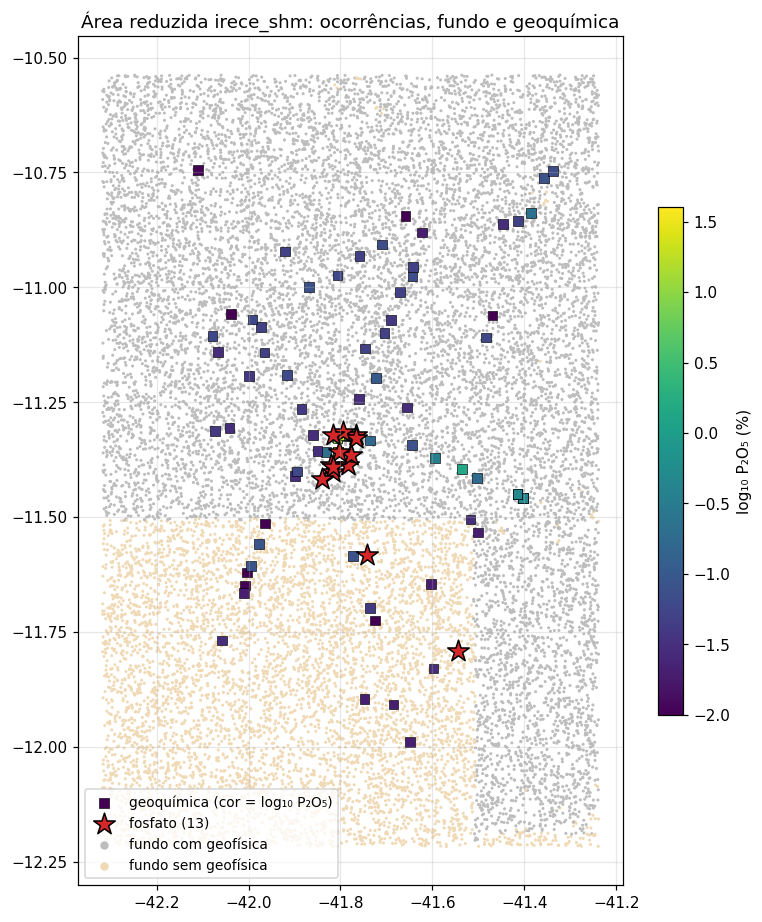

In [3]:
# [5]
fig, ax = plt.subplots(figsize=(8, 12))
ax.scatter(FUNDO.lon, FUNDO.lat, s=1, c=np.where(FUNDO.tem_geofisica == 1, '#bdbdbd', '#f0d9b5'))
sc = ax.scatter(GEOQ.lon, GEOQ.lat, s=40, c=np.log10(GEOQ.p2o5_pct.clip(lower=0.01)), cmap='viridis',
                edgecolor='k', lw=0.4, marker='s', label='geoquímica (cor = log₁₀ P₂O₅)')
ax.scatter(OC.lon, OC.lat, s=220, marker='*', c='#d62728', edgecolor='k', label=f'fosfato ({len(OC)})')
ax.scatter([], [], s=20, c='#bdbdbd', label='fundo com geofísica')
ax.scatter([], [], s=20, c='#f0d9b5', label='fundo sem geofísica')
fig.colorbar(sc, ax=ax, shrink=0.5, label='log₁₀ P₂O₅ (%)')
ax.set_aspect('equal'); ax.legend(loc='lower left', fontsize=9)
ax.set_title(f'Área reduzida {AREA}: ocorrências, fundo e geoquímica')
salvar(fig, '5', f'pontos_{AREA}')

`[5a]`

**Figura [6] — cada variável sozinha.** Para cada ocorrência, a mediana da variável
nos seus pixels é convertida em percentil do fundo (0 = menor valor da área, 100 =
maior). Cada linha é uma variável; os pontos são as ocorrências e o traço preto, a
mediana delas. A cor indica o grupo (azul ASTER, vermelho gama, verde mag, marrom
geologia).

Como ler:
- pontos espalhados em volta de 50: a variável não distingue as ocorrências da paisagem;
- pontos juntos perto de 100 (ou de 0): as ocorrências têm valor alto (ou baixo) em
  relação à área; candidata forte;
- as variáveis estão ordenadas pela distância da mediana até 50 (as de cima se destacam mais).

**Não é critério de seleção.** Olha uma variável por vez, sem modelo e sem validação;
com 11 pontos, um destaque pode ser acaso. A escolha sai das seções 4 e 5.

figura → c6_percentil_ocorrencias_irece_shm.png


lito_caboclo          0.0
lito_morro_chapeu     0.0
lito_bebedouro        0.0
lito_gabriel          0.0
lito_irece            0.0
lito_jussara          0.0
lito_cobertura        0.0
lito_tombador         0.0
dist_dobra_km         5.0
lito_nova_america    93.0
eU_ppm               88.0
phosphorite_rbd      87.0
quartz_14_12         86.0
carbonate_13_14      15.0
sultan_b             83.0
dtype: float64

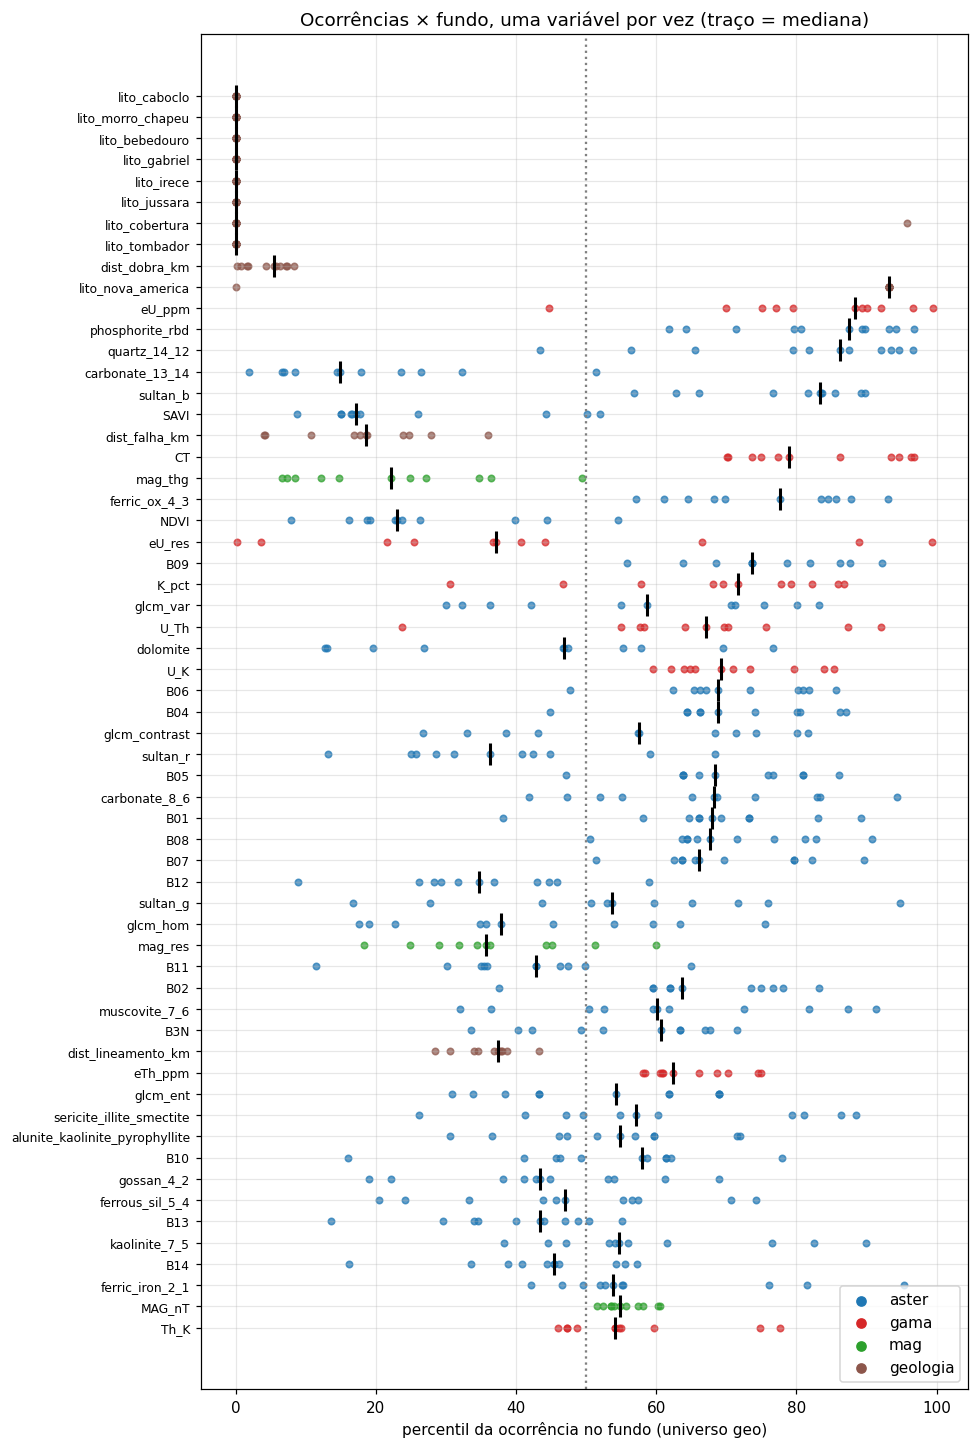

In [4]:
# [6]
# Exploração univariada (não seleciona nada): percentil da mediana de cada ocorrência
# na distribuição do fundo. 50 = típico da área; perto de 100 ou 0 = ocorrências se destacam.
p, f = UNIV['geo']
med = p.groupby('CODIGO_OBJ')[VARS].median()
pct = pd.DataFrame({v: (np.searchsorted(np.sort(f[v].values), med[v].values) / len(f)) * 100 for v in VARS},
                   index=med.index)
ordem = (pct - 50).abs().median().sort_values(ascending=False).index
cor_g = {v: c for g, c in zip(['aster', 'gama', 'mag', 'geologia'], ['#1f77b4', '#d62728', '#2ca02c', '#8c564b'])
         for v in G[g]}

fig, ax = plt.subplots(figsize=(9, 16))
for i, v in enumerate(ordem[::-1]):
    ax.scatter(pct[v], np.full(len(pct), i), s=18, c=cor_g[v], alpha=0.7)
    ax.plot(np.median(pct[v]), i, '|', c='k', ms=14, mew=2)
ax.set_yticks(range(len(ordem)), ordem[::-1], fontsize=8)
ax.axvline(50, c='grey', ls=':')
ax.set_xlabel('percentil da ocorrência no fundo (universo geo)')
for g, c in zip(['aster', 'gama', 'mag', 'geologia'], ['#1f77b4', '#d62728', '#2ca02c', '#8c564b']):
    ax.scatter([], [], c=c, label=g)
ax.legend(loc='lower right'); ax.set_title('Ocorrências × fundo, uma variável por vez (traço = mediana)')
salvar(fig, '6', f'percentil_ocorrencias_{AREA}')
pct.median().loc[ordem].round(0).head(15)

`[7]`

## 2. Redundância

Spearman entre as variáveis **no fundo** (a paisagem, sem usar as ocorrências),
agrupamento hierárquico completo e corte em |r| = `R_MAX`: dentro de cada grupo
todas as variáveis têm |r| ≥ `R_MAX` entre si. Fica uma por grupo, pela ordem de
`PRIORIDADE` (o SHAP da R2, que não usa estes pontos). O corte é feito dentro de
cada grupo de variáveis (aster, gama, mag, geologia), para a ablação da seção 4
comparar grupos inteiros. Variáveis constantes na área saem antes.

**Regra de decisão (`reduzir`).**
1. Tira as variáveis constantes no fundo (ex.: uma unidade litológica ausente da área).
2. Calcula o Spearman entre todas as variáveis do grupo, só no fundo.
3. Agrupa por ligação completa com distância 1 − |r| e corta em 1 − `R_MAX`.
   Com ligação completa, todo par dentro de um grupo tem |r| ≥ `R_MAX`.
4. Em cada grupo fica o primeiro na ordem de `PRIORIDADE`; o resto é listado como
   "representante ← removidas".

**Figura [8].** À esquerda, o dendrograma: variáveis que se juntam à esquerda da
linha vermelha tracejada (|r| = `R_MAX`) são redundantes e viram uma só. À direita,
a matriz de Spearman na mesma ordem: azul forte = correlação positiva, vermelho
forte = negativa; blocos escuros na diagonal são os grupos redundantes.


aster    : 36 → 20
    B10 ← ['B11', 'B12', 'B13', 'B14']
    B09 ← ['B04', 'B05', 'B06', 'B07', 'B08']
    B01 ← ['B02']
    ferrous_sil_5_4 ← ['alunite_kaolinite_pyrophyllite']
    SAVI ← ['NDVI', 'sultan_b']
    glcm_contrast ← ['glcm_hom', 'glcm_var']
    dolomite ← ['muscovite_7_6']
gama     : 8 → 8
mag      : 3 → 3
geologia : 12 → 11
    dist_falha_km ← ['dist_lineamento_km']
figura → c8_redundancia_irece_shm.png
pares fortes entre grupos: nenhum


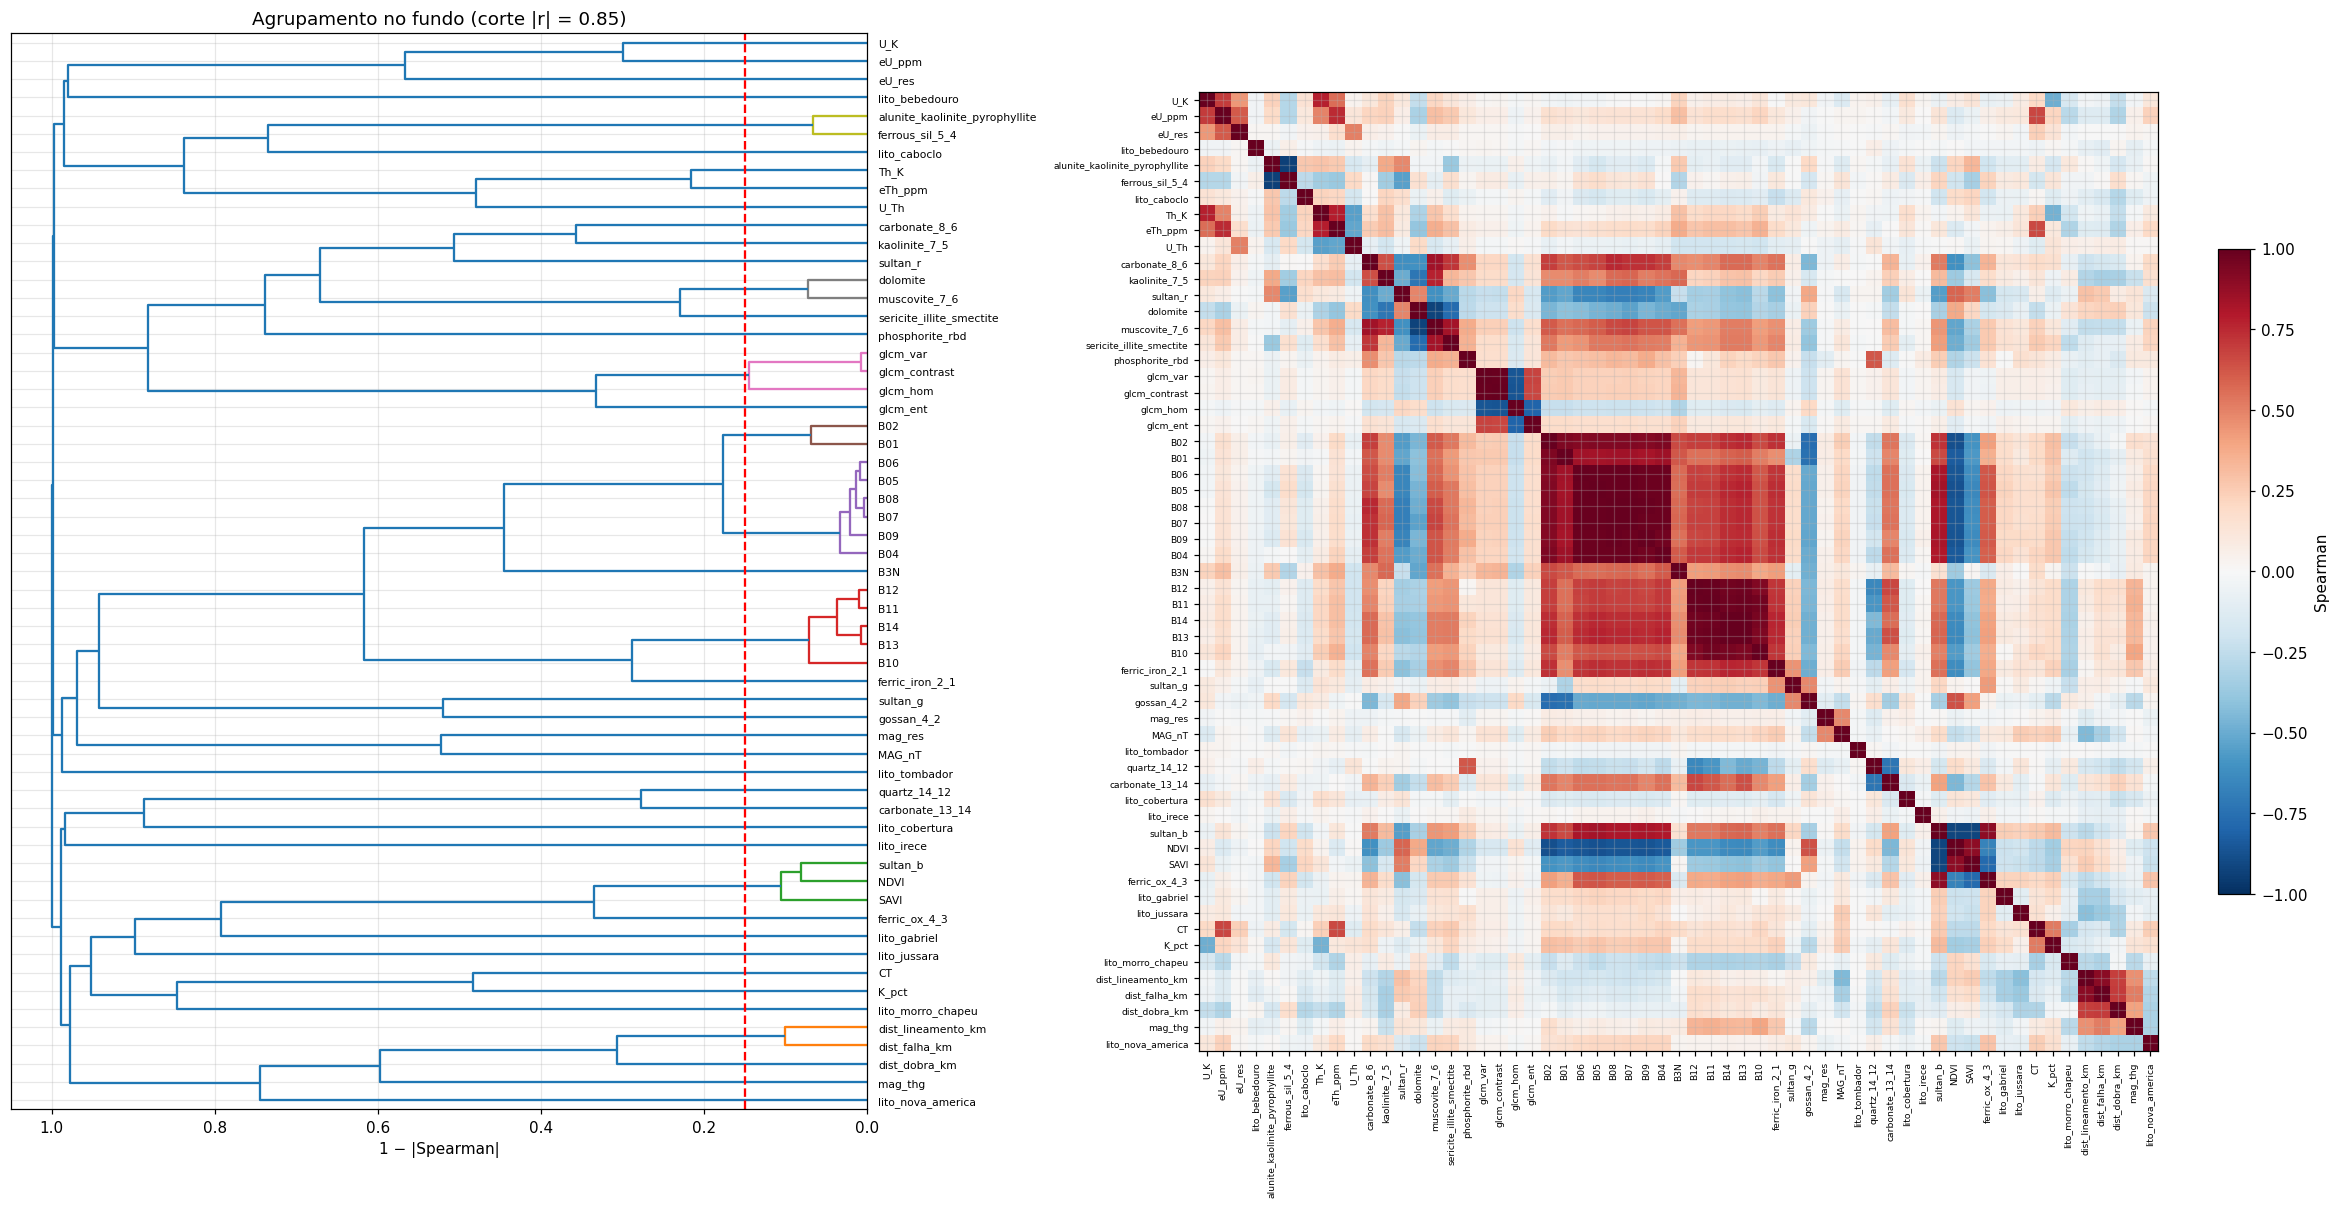

In [5]:
# [8]
def reduzir(cols, f):
    """(mantidas, grupos {representante: membros}) com |Spearman| ≥ R_MAX no fundo f."""
    cols = [c for c in cols if f[c].nunique() > 1]
    if len(cols) < 2:
        return cols, {c: [c] for c in cols}
    r = f[cols].corr(method='spearman').fillna(0).values
    d = 1 - np.abs(r); np.fill_diagonal(d, 0)
    lab = hierarchy.fcluster(hierarchy.linkage(squareform(d, checks=False), 'complete'), 1 - R_MAX, 'distance')
    grupos = {}
    for k in np.unique(lab):
        membros = sorted([cols[i] for i in np.where(lab == k)[0]], key=prioridade)
        grupos[membros[0]] = membros
    return sorted(grupos, key=lambda v: cols.index(v)), grupos

f_geo = UNIV['geo'][1]
RED, GRUPOS_RED = {}, {}
for g in ['aster', 'gama', 'mag', 'geologia']:
    RED[g], GRUPOS_RED[g] = reduzir(G[g], f_geo)
    juntos = {k: m for k, m in GRUPOS_RED[g].items() if len(m) > 1}
    print(f'{g:9s}: {len(G[g])} → {len(RED[g])}' + ''.join(f'\n    {k} ← {m[1:]}' for k, m in juntos.items()))

# figura: dendrograma de todas as variáveis (linha = corte R_MAX)
cols = [c for c in VARS if f_geo[c].nunique() > 1]
r = f_geo[cols].corr(method='spearman').fillna(0)
d = 1 - r.abs().values; np.fill_diagonal(d, 0)
Z = hierarchy.linkage(squareform(d, checks=False), 'complete')
fig, axs = plt.subplots(1, 2, figsize=(22, 11), gridspec_kw={'width_ratios': [1, 1.4]})
dn = hierarchy.dendrogram(Z, labels=cols, orientation='left', ax=axs[0], color_threshold=1 - R_MAX,
                          leaf_font_size=7)
axs[0].axvline(1 - R_MAX, c='r', ls='--'); axs[0].set_xlabel('1 − |Spearman|')
axs[0].set_title(f'Agrupamento no fundo (corte |r| = {R_MAX})')
ordem = dn['ivl'][::-1]
im = axs[1].imshow(r.loc[ordem, ordem], cmap='RdBu_r', vmin=-1, vmax=1)
axs[1].set_xticks(range(len(ordem)), ordem, rotation=90, fontsize=6)
axs[1].set_yticks(range(len(ordem)), ordem, fontsize=6)
fig.colorbar(im, ax=axs[1], shrink=0.6, label='Spearman')
fig.tight_layout()
salvar(fig, '8', f'redundancia_{AREA}')

# pares fortes entre grupos diferentes (ficam os dois; só aviso)
grupo_de = {v: g for g in G for v in G[g]}
fortes = [(a, b, r.loc[a, b]) for i, a in enumerate(cols) for b in cols[i + 1:]
          if grupo_de[a] != grupo_de[b] and abs(r.loc[a, b]) >= R_MAX]
print('pares fortes entre grupos:', fortes or 'nenhum')

`[9]`

## 3. Validação espacial

**Folds.** As 11 ocorrências com geofísica estão todas num trecho de ~8 × 10 km
(vizinha mais próxima a 0,6–3,2 km); agrupar por distância junta todas num fold só.
Por isso:
- **ocorrências**: k-means das coordenadas em `N_FOLDS` grupos (~2 ocorrências
  vizinhas por grupo); cada grupo é um fold;
- **fundo e geoquímica**: blocos de `BLOCO_KM` km sorteados entre os folds; o fundo
  do fold de teste nunca entra no treino.

**Limite que não tem como contornar.** Como todas as ocorrências são de um mesmo
distrito, a ocorrência de teste sempre tem vizinhas a 1–3 km no treino, às vezes no
mesmo pixel de gama de 500 m. As métricas medem "o modelo reconhece o distrito",
não "o modelo acha fosfato em outro lugar". Comparar conjuntos entre si (ablação)
continua válido; o valor absoluto da AUC é otimista. O teste independente de
verdade é a geoquímica da seção 6.

**Modelos.** RF e GTB com os parâmetros do `avaliar_maxent.ipynb` (o GEE usa os
mesmos: 300 árvores no RF, 80 no GTB com passo 0,1).

**Métricas** (fora da amostra), sobre a mediana de p de cada ocorrência:
- `auc_ponto`: ocorrência × fundo; intervalo de 90% por bootstrap das ocorrências;
- `ap_ganho`: precisão média ÷ prevalência (1 = acaso);
- `boyce`: índice de Boyce contínuo (pixels de presença);
- `top10`: fração das ocorrências nos 10% da área com maior p.

**Funções de decisão.**
- `montar_folds`: k-means das coordenadas das ocorrências em `N_FOLDS` grupos; o
  fundo vai para o fold do seu bloco de `BLOCO_KM` km.
- `oof`: para cada fold, treina com todo o resto e prediz o fold. No fim, todo pixel
  de presença, de fundo (e de geoquímica, quando passada) tem um p de um modelo que
  não viu a região dele.
- `metricas`: resume cada ocorrência pela mediana do p nos seus pixels, para que as
  ~100 cópias do mesmo pixel de gama contem como uma observação.

**Figura [10] — folds.** Cada cor é um fold: as estrelas são as ocorrências dele e
os pontos pequenos, o fundo que sai junto. A legenda dá quantas ocorrências e
quantos pixels de fundo cada fold tem. Um fold com poucos pixels de fundo deixa a
métrica dele instável; os blocos aparecem como um tabuleiro de cores.


figura → c10_folds_irece_shm.png


PosixPath('/home/superuser/Dados/proj/prosprectra/modelagem_prospectra_mine/src/modeling/models/figuras_selecao_AR/c10_folds_irece_shm.png')

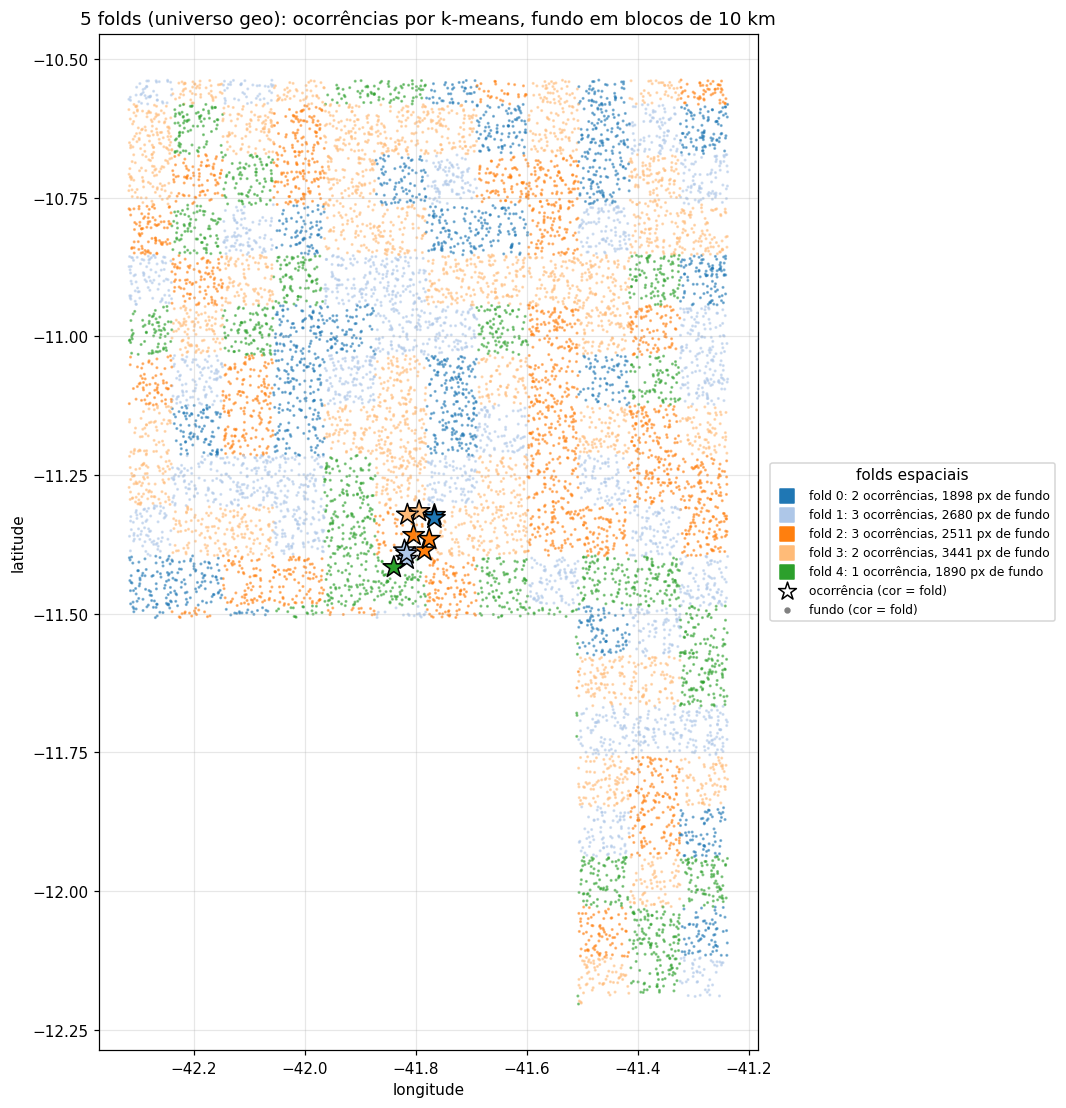

In [6]:
# [10]
RF_PARAMS = dict(n_estimators=300, min_samples_leaf=10, max_features='sqrt',
                 class_weight='balanced', n_jobs=-1, random_state=SEED)
GTB_PARAMS = dict(learning_rate=0.1, max_iter=80, max_depth=4, min_samples_leaf=50,
                  l2_regularization=1.0, class_weight='balanced', random_state=SEED)

class RFPresFundo:
    def fit(self, Xp, Xf):
        self.rf = RandomForestClassifier(**RF_PARAMS).fit(np.r_[Xp, Xf], np.r_[np.ones(len(Xp)), np.zeros(len(Xf))])
        return self
    def predict(self, X):
        return self.rf.predict_proba(X)[:, 1]

class GTBPresFundo:
    def fit(self, Xp, Xf):
        self.gb = HistGradientBoostingClassifier(**GTB_PARAMS).fit(np.r_[Xp, Xf], np.r_[np.ones(len(Xp)), np.zeros(len(Xf))])
        return self
    def predict(self, X):
        return self.gb.predict_proba(X)[:, 1]

MODELOS_CLS = {'RF': RFPresFundo, 'GTB': GTBPresFundo}
COR_MOD = {'RF': 'k', 'GTB': '#17becf'}

def _km(lon, lat, lat0):
    return np.c_[np.asarray(lon) * 111.32 * np.cos(np.deg2rad(lat0)), np.asarray(lat) * 110.57]

def _fold_bloco(t, lat0, k):
    """fold de cada pixel pelo bloco de BLOCO_KM km que o contém; o sorteio depende só do
    bloco, então fundo e geoquímica do mesmo bloco caem sempre no mesmo fold."""
    b = (_km(t.lon, t.lat, lat0) // BLOCO_KM).astype(int)
    return pd.Series([int(np.random.default_rng([SEED, bx + 10**4, by + 10**4]).integers(k)) for bx, by in b],
                     index=t.index)

def montar_folds(p, f, extra=None):
    """fold de cada pixel de presença, de fundo (e de extra). Ocorrências: k-means das
    coordenadas em N_FOLDS grupos (vizinhas juntas). Fundo e extra: blocos de BLOCO_KM km."""
    oc = p.groupby('CODIGO_OBJ')[['lon', 'lat']].mean()
    k = min(N_FOLDS, len(oc))
    if k < 2:
        raise ValueError(f'só {len(oc)} ocorrência(s): não dá para validar fora da amostra')
    lat0 = oc.lat.mean()
    g = pd.Series(KMeans(k, n_init=10, random_state=SEED).fit_predict(_km(oc.lon, oc.lat, lat0)), index=oc.index)
    return (p.CODIGO_OBJ.map(g), _fold_bloco(f, lat0, k),
            _fold_bloco(extra, lat0, k) if extra is not None else None)

_CACHE_CL = {}

def agrupar_fundo(p_tr, f_tr):
    """k-means (K_FUNDO clusters) do fundo nas VARS_CLUSTER padronizadas (média 0, desvio 1
    no fundo) e distância euclidiana de cada cluster ao "cluster fosfato" (K + 1), cujo
    centro é a média das medianas de cada ocorrência no mesmo espaço padronizado.
    Não depende das variáveis do modelo: o resultado fica em cache por fold."""
    chave = (tuple(sorted(p_tr.CODIGO_OBJ.unique())), len(f_tr), int(f_tr.index.values.sum()), K_FUNDO)
    if chave in _CACHE_CL:
        return _CACHE_CL[chave]
    cols = VARS_CLUSTER
    if f_tr[cols].isna().any().any() or p_tr[cols].isna().any().any():
        raise ValueError('VARS_CLUSTER com NaN: o agrupamento exige o universo geo (tem_geofisica = 1)')
    sc = StandardScaler().fit(f_tr[cols])
    X = sc.transform(f_tr[cols])
    km = KMeans(K_FUNDO, n_init=10, random_state=SEED).fit(X)
    lab, centros, k = km.labels_, km.cluster_centers_, K_FUNDO
    med = sc.transform(p_tr.groupby('CODIGO_OBJ')[cols].median())
    c_oc = med.mean(0)                                            # centro do cluster fosfato
    raio = np.linalg.norm(med - c_oc, axis=1).max()               # ocorrência mais afastada do centro
    lab_oc = np.linalg.norm(med[:, None] - centros[None], axis=2).argmin(1)   # cluster mais próximo
    res = {'cols': cols, 'centros': pd.DataFrame(centros, columns=cols), 'c_oc': pd.Series(c_oc, index=cols),
           'dist': np.linalg.norm(centros - c_oc, axis=1), 'raio': raio,
           'n_oc': np.bincount(lab_oc, minlength=k), 'frac': np.bincount(lab, minlength=k) / len(lab),
           'lab': pd.Series(lab, index=f_tr.index), 'media': sc.mean_, 'desvio': sc.scale_}
    _CACHE_CL[chave] = res
    return res

def fundo_treino(p_tr, f_tr, feats=None, modo=None, info=False):
    """Fundo usado no TREINO. 'aleatorio' = todo. 'cluster' = só os clusters de fundo
    (agrupar_fundo) sem ocorrência e com o centro além do raio do fosfato (a distância
    da ocorrência mais afastada ao centro das ocorrências). Se somarem menos de
    FRAC_MIN_FUNDO, entram os próximos mais distantes sem ocorrência. Usa só as
    ocorrências de treino (p_tr), para o fold de teste não escolher o próprio fundo.
    Fundo sem geofísica (conjuntos da área toda): não há como agrupar, fica o aleatório."""
    modo = modo or FUNDO_MODO
    if modo == 'cluster' and f_tr[VARS_CLUSTER].isna().any().any():
        modo = 'aleatorio'
    if modo == 'aleatorio':
        return (f_tr, None) if info else f_tr
    r = agrupar_fundo(p_tr, f_tr)
    dist, frac, n_oc = r['dist'], r['frac'], r['n_oc']
    longe = (dist > r['raio']) & (n_oc == 0)
    completou = np.zeros_like(longe)
    if frac[longe].sum() < FRAC_MIN_FUNDO:
        for c in np.argsort(-dist):
            if n_oc[c] == 0 and not longe[c]:
                longe[c] = completou[c] = True
                if frac[longe].sum() >= FRAC_MIN_FUNDO:
                    break
    sel = f_tr[longe[r['lab'].values]]
    return (sel, {**r, 'longe': longe, 'completou': completou}) if info else sel

def oof(p, f, feats, Modelo, extra=None):
    """p fora da amostra para presença, fundo (e extra, ex.: geoquímica). O treino usa o
    fundo de fundo_treino; a predição e as métricas, TODO o fundo do fold (aleatório)."""
    fp, ff, fe = montar_folds(p, f, extra)
    op, of = pd.Series(np.nan, index=p.index), pd.Series(np.nan, index=f.index)
    oe = pd.Series(np.nan, index=extra.index) if extra is not None else None
    for k in sorted(fp.unique()):
        p_tr = p[fp != k]
        m = Modelo().fit(p_tr[feats].values, fundo_treino(p_tr, f[ff != k], feats)[feats].values)
        op[fp == k] = m.predict(p.loc[fp == k, feats].values)
        if (ff == k).any():
            of[ff == k] = m.predict(f.loc[ff == k, feats].values)
        if extra is not None and (fe == k).any():
            oe[fe == k] = m.predict(extra.loc[fe == k, feats].values)
    return op, of, oe

def boyce(pp, pf, n_janelas=91, largura=0.1):
    """Boyce contínuo com janelas de área igual (mesmo do avaliar_maxent)."""
    u = np.searchsorted(np.sort(pf), pp) / len(pf)
    cent = np.linspace(largura / 2, 1 - largura / 2, n_janelas)
    pe = np.array([((u >= c - largura / 2) & (u < c + largura / 2)).mean() / largura for c in cent])
    return spearmanr(cent, pe).statistic

def metricas(op, of, p):
    pp, pf = op.values, of.values
    pt = op.groupby(p.CODIGO_OBJ).median().values
    y = np.r_[np.ones(len(pt)), np.zeros(len(pf))]
    auc = roc_auc_score(y, np.r_[pt, pf])
    boot = [roc_auc_score(y, np.r_[rng.choice(pt, len(pt)), pf]) for _ in range(N_BOOT)]
    return {'auc_ponto': auc, 'auc_p05': np.quantile(boot, 0.05), 'auc_p95': np.quantile(boot, 0.95),
            'ap_ganho': average_precision_score(y, np.r_[pt, pf]) / y.mean(),
            'boyce': boyce(pp, pf), 'top10': (pt >= np.quantile(pf, 0.9)).mean(), 'ocorrencias': len(pt)}

# figura: folds no universo geo
p, f = UNIV['geo']
fp, ff, _ = montar_folds(p, f)
fig, ax = plt.subplots(figsize=(11, 12))
cm = plt.get_cmap('tab20')
ax.scatter(f.lon, f.lat, s=1, c=[cm(k % 20) for k in ff], alpha=0.5)
oc = p.groupby('CODIGO_OBJ')[['lon', 'lat']].mean()
ax.scatter(oc.lon, oc.lat, s=220, marker='*', c=[cm(fp[p.CODIGO_OBJ == c].iloc[0] % 20) for c in oc.index],
           edgecolor='k')
for k in sorted(fp.unique()):
    n_oc = p.loc[fp == k, 'CODIGO_OBJ'].nunique()
    ax.scatter([], [], s=80, marker='s', color=cm(k % 20),
               label=f'fold {k}: {n_oc} ocorrência{"s" if n_oc > 1 else ""}, {(ff == k).sum()} px de fundo')
ax.scatter([], [], s=150, marker='*', c='w', edgecolor='k', label='ocorrência (cor = fold)')
ax.scatter([], [], s=10, c='grey', label='fundo (cor = fold)')
ax.legend(loc='center left', bbox_to_anchor=(1.01, 0.5), fontsize=8, title='folds espaciais')
ax.set_xlabel('longitude'); ax.set_ylabel('latitude')
ax.set_aspect('equal'); ax.set_title(f'{fp.nunique()} folds (universo geo): ocorrências por k-means, fundo em blocos de {BLOCO_KM} km')
salvar(fig, '10', f'folds_{AREA}')

`[10a]`

**Fundo por cluster (`FUNDO_MODO = 'cluster'`).** O fundo aleatório inclui pixels
parecidos com as ocorrências (a mesma rocha sem depósito conhecido, ou com depósito
ainda não achado). Treinar com eles como "não fosfato" empurra o modelo a separar
detalhes finos e ruidosos. A alternativa (pseudo-ausência por perfil ambiental,
Engler et al. 2004; Senay et al. 2013):
1. agrupa todos os pixels de fundo com geofísica por **k-means com `K_FUNDO` = 10
   clusters**, nas 14 variáveis de `VARS_CLUSTER`: gama (5), mag (3) e ASTER (6:
   Sultan, B10, quartzo, phosphorite_rbd; **sem litologia**), padronizadas no fundo
   (média 0, desvio 1), para todas pesarem igual na distância;
2. o **cluster fosfato** é o cluster K + 1, formado pelas ocorrências: centro = média
   das medianas de cada ocorrência (cada ocorrência pesa igual), no mesmo espaço
   padronizado;
3. distância de cada cluster = euclidiana do seu centro ao centro do fosfato;
4. **raio do fosfato** = distância da ocorrência mais afastada ao centro: o envelope
   das ocorrências reais;
5. ficam no fundo de treino só os clusters **sem ocorrência e com o centro além do
   raio**. Se eles somarem menos de `FRAC_MIN_FUNDO` do fundo, entram os próximos
   mais distantes sem ocorrência (barra hachurada na figura).

**Regras para não se enganar.**
- Na validação, refeito dentro de cada fold, só com as ocorrências de treino. A
  figura, a tabela e o fundo do export usam todas as ocorrências.
- Conjuntos da área toda (`*_area_toda`): ~1/3 do fundo não tem gama nem mag, então
  não entra no agrupamento; o treino desses conjuntos usa o fundo aleatório.
- Só o **treino** usa o fundo filtrado. AUC, Boyce e top10 são sempre medidos contra
  o fundo aleatório inteiro do fold. Medir contra o fundo distante daria AUC perto
  de 1 sem significar nada, porque separar ocorrência de paisagem muito diferente é fácil.
- Efeito esperado no mapa: p alto em áreas maiores (tudo que parece com as
  ocorrências), com contraste menor entre elas. Para comparar, rode o notebook com
  `'aleatorio'` e `'cluster'`: figuras e CSVs levam o modo no nome.

**Figura [10b].** No universo geo, com todas as ocorrências. À esquerda, o mapa:
cinza = fundo de treino; laranja = fundo excluído. À direita, o ranking dos clusters,
do mais próximo ao mais distante do fosfato: vermelho = tem ocorrência, laranja =
excluído (dentro do raio), cinza = fundo de treino; hachurado = entrou só para
completar `FRAC_MIN_FUNDO`. A linha tracejada é o raio do fosfato. O texto em cada
barra dá a fração do fundo e quantas ocorrências caem no cluster.

k-means: 10 clusters em 14 variáveis; raio do fosfato 3.73; fundo de treino 3252 de 12420 pixels (26%); clusters com ocorrência: [0, 2, 8]
figura → c10b_fundo_cluster_irece_shm_k10.png


PosixPath('/home/superuser/Dados/proj/prosprectra/modelagem_prospectra_mine/src/modeling/models/figuras_selecao_AR/c10b_fundo_cluster_irece_shm_k10.png')

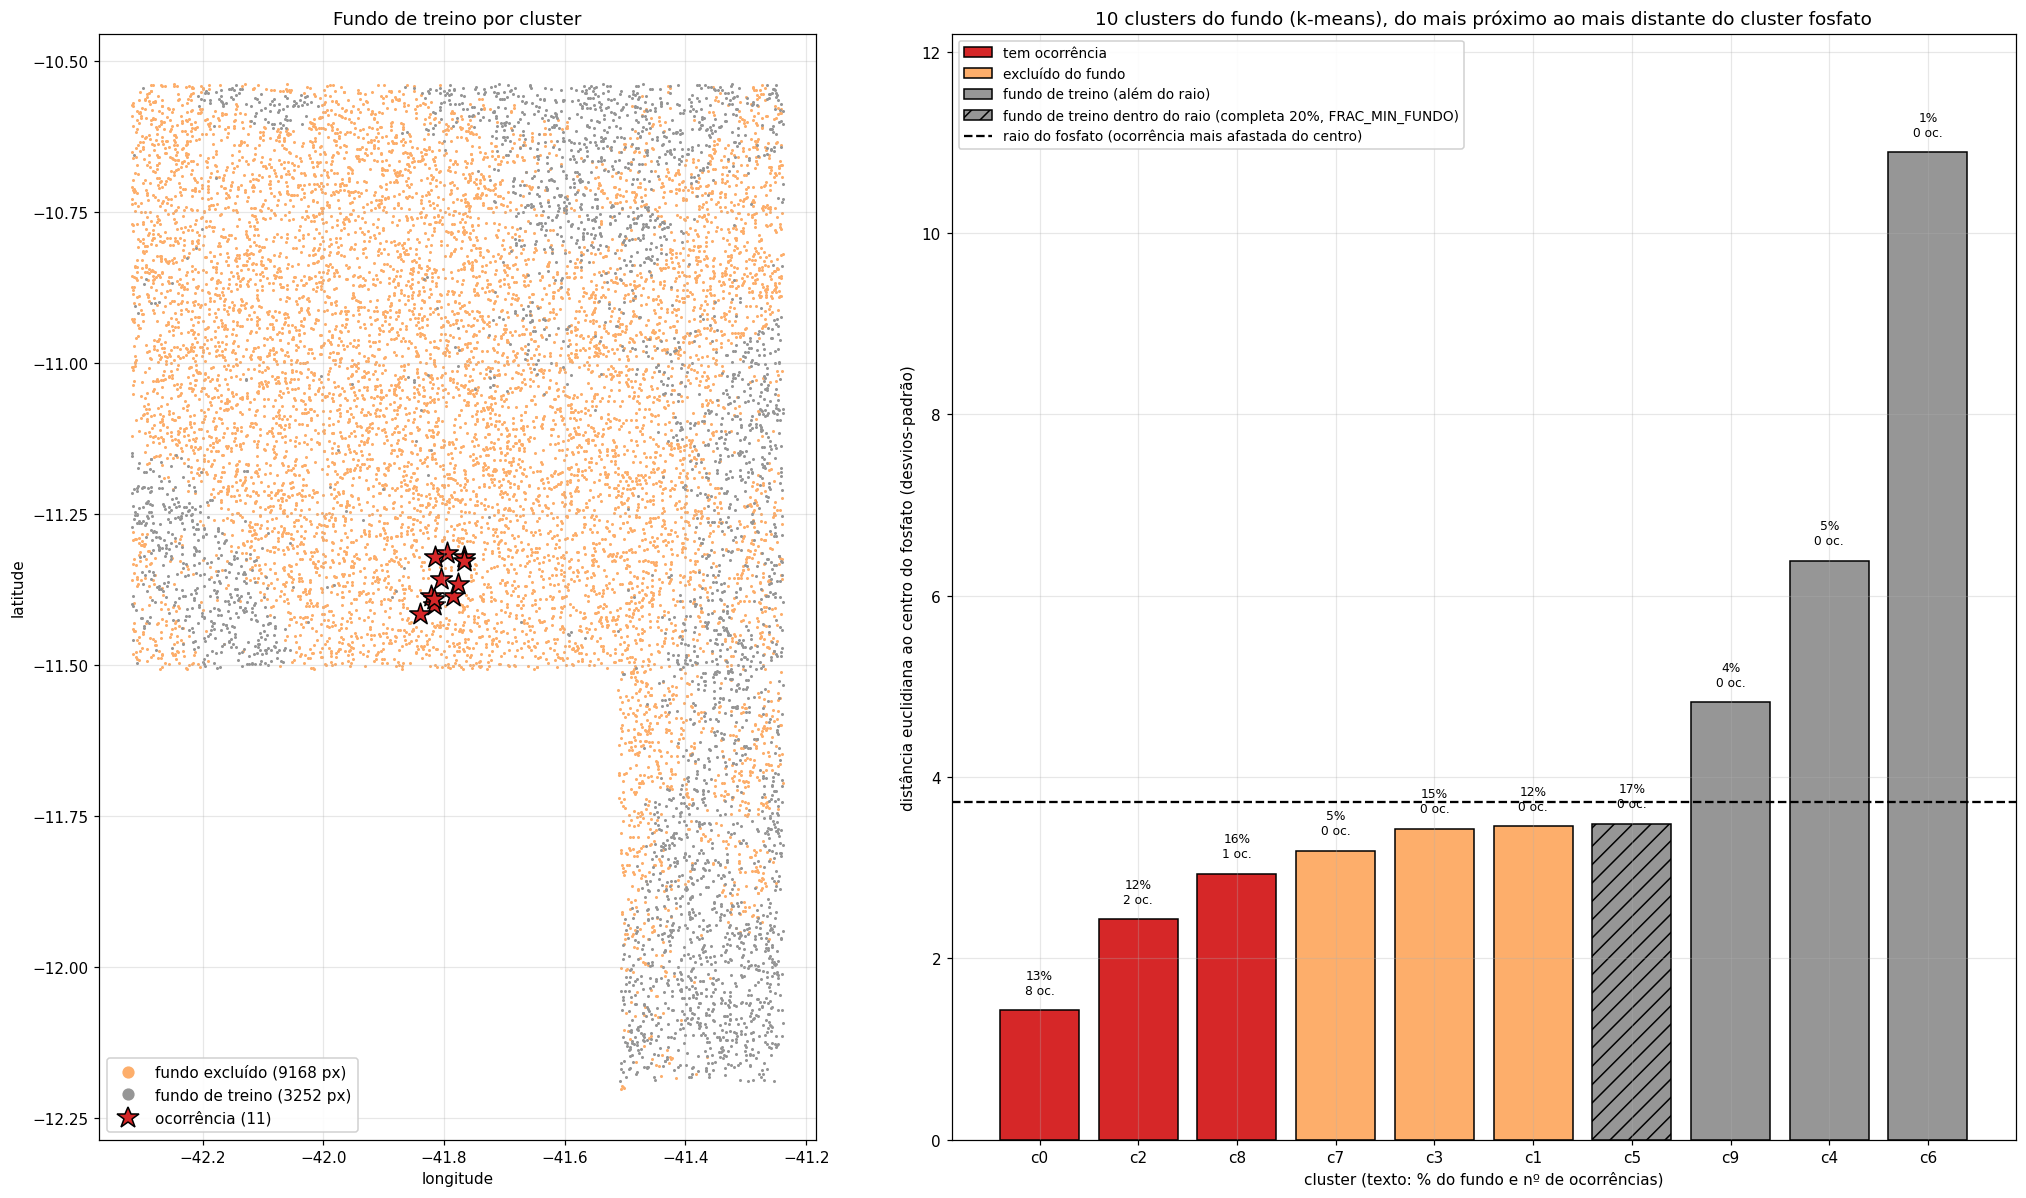

In [7]:
# [10b]
p, f = UNIV['geo']
sel, inf = fundo_treino(p, f, modo='cluster', info=True)
K_CL = len(inf['dist'])
fica = f.index.isin(sel.index)
print(f'k-means: {K_CL} clusters em {len(inf["cols"])} variáveis; raio do fosfato {inf["raio"]:.2f}; '
      f'fundo de treino {fica.sum()} de {len(f)} pixels ({fica.mean():.0%}); '
      f'clusters com ocorrência: {np.where(inf["n_oc"] > 0)[0].tolist()}')

from matplotlib.lines import Line2D
from matplotlib.patches import Patch

C_EXC, C_TR, C_OC = '#fdae6b', '#969696', '#d62728'
fig, axs = plt.subplots(1, 2, figsize=(19, 11), gridspec_kw={'width_ratios': [1, 1.2]})
ax = axs[0]
ax.scatter(f.lon[~fica], f.lat[~fica], s=1, c=C_EXC)
ax.scatter(f.lon[fica], f.lat[fica], s=1, c=C_TR)
oc = p.groupby('CODIGO_OBJ')[['lon', 'lat']].mean()
ax.scatter(oc.lon, oc.lat, s=220, marker='*', c=C_OC, edgecolor='k')
ax.legend(handles=[
    Line2D([], [], ls='', marker='o', ms=7, color=C_EXC, label=f'fundo excluído ({(~fica).sum()} px)'),
    Line2D([], [], ls='', marker='o', ms=7, color=C_TR, label=f'fundo de treino ({fica.sum()} px)'),
    Line2D([], [], ls='', marker='*', ms=15, mfc=C_OC, mec='k', label=f'ocorrência ({len(oc)})'),
], loc='lower left', fontsize=10, framealpha=0.9)
ax.set_aspect('equal'); ax.set_xlabel('longitude'); ax.set_ylabel('latitude')
ax.set_title('Fundo de treino por cluster')

ax = axs[1]
ordem = np.argsort(inf['dist'])
completou = inf['completou']
for j, c in enumerate(ordem):
    cor = C_OC if inf['n_oc'][c] else (C_TR if inf['longe'][c] else C_EXC)
    ax.bar(j, inf['dist'][c], color=cor, edgecolor='k', hatch='//' if completou[c] else None)
    ax.text(j, inf['dist'][c] + 0.15, f"{inf['frac'][c]:.0%}\n{inf['n_oc'][c]} oc.", ha='center', va='bottom', fontsize=8)
ax.axhline(inf['raio'], c='k', ls='--')
ax.set_xticks(range(K_CL), [f'c{c}' for c in ordem])
ax.set_xlabel('cluster (texto: % do fundo e nº de ocorrências)')
ax.set_ylabel('distância euclidiana ao centro do fosfato (desvios-padrão)')
alca = [Patch(fc=C_OC, ec='k', label='tem ocorrência'),
        Patch(fc=C_EXC, ec='k', label='excluído do fundo'),
        Patch(fc=C_TR, ec='k', label='fundo de treino (além do raio)'),
        Line2D([], [], c='k', ls='--', label='raio do fosfato (ocorrência mais afastada do centro)')]
if completou.any():
    alca.insert(3, Patch(fc=C_TR, ec='k', hatch='//',
                         label=f'fundo de treino dentro do raio (completa {FRAC_MIN_FUNDO:.0%}, FRAC_MIN_FUNDO)'))
ax.legend(handles=alca, loc='upper left', fontsize=9, framealpha=0.9)
ax.set_ylim(0, max(inf['dist'].max(), inf['raio']) * 1.12)
ax.set_title(f'{K_CL} clusters do fundo (k-means), do mais próximo ao mais distante do cluster fosfato')
fig.tight_layout()
salvar(fig, '10b', f'fundo_cluster_{AREA}_k{K_CL}')


`[10c]`

**Tabela [10c] — ranking dos clusters**, do mais próximo ao mais distante do
cluster fosfato. Distâncias euclidianas nas `VARS_CLUSTER` padronizadas, em
desvios-padrão:
- `dist_fosfato`: do centro do cluster ao centro das ocorrências; comparada ao
  raio do fosfato (impresso acima da tabela);
- `variavel_dominante` e `parcela_dominante`: a variável que mais contribui para a
  distância e a fração da distância² que vem dela (perto de 1 = longe por uma
  variável só);
- primeira linha = o **cluster fosfato** (K + 1, as ocorrências): distância 0, `pixels`
  = pixels de presença;
- `situacao`: ocorrência (nunca é fundo), excluído (dentro do raio), treino (entra
  no fundo do RF/GTB) ou treino_completa (dentro do raio, entrou para completar
  `FRAC_MIN_FUNDO`).

In [8]:
# [10c]
dif2 = (inf['centros'] - inf['c_oc']) ** 2
TAB_CL = pd.DataFrame({
    'pixels': inf['lab'].value_counts().reindex(range(K_CL), fill_value=0).values,
    'pct_fundo': (inf['frac'] * 100).round(1),
    'ocorrencias': inf['n_oc'],
    'dist_fosfato': inf['dist'],
    'variavel_dominante': dif2.idxmax(1).values,
    'parcela_dominante': (dif2.max(1) / dif2.sum(1)).values,
    'situacao': np.select([inf['n_oc'] > 0, inf['completou'], inf['longe']],
                          ['ocorrência', 'treino_completa', 'treino'], 'excluído'),
}, index=[f'c{c}' for c in range(K_CL)]).sort_values('dist_fosfato')
TAB_CL.insert(0, 'posto', range(1, K_CL + 1))
fosf = pd.DataFrame({'posto': 0, 'pixels': len(p), 'pct_fundo': 0.0, 'ocorrencias': p.CODIGO_OBJ.nunique(),
                     'dist_fosfato': 0.0, 'variavel_dominante': '', 'parcela_dominante': np.nan,
                     'situacao': 'cluster fosfato'}, index=['fosfato'])
TAB_CL = pd.concat([fosf, TAB_CL])
print(f'k-means: {K_CL} clusters + cluster fosfato | raio do fosfato {inf["raio"]:.2f} | variáveis: {", ".join(inf["cols"])}')
print({k: f'{v} clusters, {TAB_CL.pct_fundo[TAB_CL.situacao == k].sum():.0f}% do fundo'
       for k, v in TAB_CL.situacao[1:].value_counts().items()})
TAB_CL.round(2)

k-means: 10 clusters + cluster fosfato | raio do fosfato 3.73 | variáveis: eU_ppm, eTh_ppm, U_Th, Th_K, eU_res, MAG_nT, mag_res, mag_thg, sultan_r, sultan_g, sultan_b, B10, quartz_14_12, phosphorite_rbd
{'ocorrência': '3 clusters, 42% do fundo', 'excluído': '3 clusters, 32% do fundo', 'treino': '3 clusters, 9% do fundo', 'treino_completa': '1 clusters, 17% do fundo'}


,posto,pixels,pct_fundo,ocorrencias,dist_fosfato,variavel_dominante,parcela_dominante,situacao
fosfato,0,1100,0.0,11,0.00,,NaN,cluster fosfato
c0,1,1647,13.3,8,1.43,eU_ppm,0.44,ocorrência
c2,2,1542,12.4,2,2.43,eU_res,0.43,ocorrência
c8,3,2027,16.3,1,2.93,quartz_14_12,0.31,ocorrência
c7,4,671,5.4,0,3.19,eU_ppm,0.28,excluído
c3,5,1834,14.8,0,3.43,eU_ppm,0.33,excluído
c1,6,1447,11.7,0,3.46,mag_thg,0.28,excluído
c5,7,2094,16.9,0,3.48,eU_ppm,0.28,treino_completa
c9,8,450,3.6,0,4.82,U_Th,0.49,treino
c4,9,625,5.0,0,6.39,sultan_b,0.26,treino


`[10d]`

**Tabela [10d] — quantas amostras entram em cada etapa** (universo geo).
- `pres_treino`: pixels de presença do treino do fold (`N_POR_PONTO` × ocorrências de treino);
- `fundo_disponivel`: fundo dos blocos de treino do fold;
- `fundo_treino`: o que sobra depois do filtro por cluster (só esses treinam o modelo);
- `fundo_avaliacao`: fundo dos blocos de teste, **todo** ele, sem filtro (é contra ele
  que AUC, Boyce e top10 são medidos).

No notebook, RF e GTB usam `class_weight='balanced'`: presença e fundo pesam igual no
total, qualquer que seja a proporção. No export do GEE não há peso; o fundo é
sorteado em `FATOR_FUNDO` = 3 × a presença, entre os pixels elegíveis (linha
`export`, com todas as ocorrências).

In [9]:
# [10d]
p, f = UNIV['geo']
fp, ff, _ = montar_folds(p, f)
CONT = []
for k in sorted(fp.unique()):
    p_tr, f_tr = p[fp != k], f[ff != k]
    CONT.append({'etapa': f'fold {k}', 'ocorrencias_teste': p[fp == k].CODIGO_OBJ.nunique(),
                 'pres_treino': len(p_tr), 'fundo_disponivel': len(f_tr),
                 'fundo_treino': len(fundo_treino(p_tr, f_tr)), 'fundo_avaliacao': int((ff == k).sum())})
eleg = len(fundo_treino(p, f))
FATOR_FUNDO = 3   # o mesmo do exportar_favorabilidade_AR.py
CONT.append({'etapa': 'export', 'ocorrencias_teste': 0, 'pres_treino': len(p), 'fundo_disponivel': len(f),
             'fundo_treino': min(eleg, FATOR_FUNDO * len(p)), 'fundo_avaliacao': 0})
CONT = pd.DataFrame(CONT).set_index('etapa')
CONT['pct_fundo_treino'] = (100 * CONT.fundo_treino / CONT.fundo_disponivel).round(0)
print(f'fundo elegível com todas as ocorrências: {eleg} de {len(f)} px; '
      f'o export sorteia {FATOR_FUNDO} × {len(p)} = {FATOR_FUNDO * len(p)} deles')
CONT

fundo elegível com todas as ocorrências: 3252 de 12420 px; o export sorteia 3 × 1100 = 3300 deles


,ocorrencias_teste,pres_treino,fundo_disponivel,fundo_treino,fundo_avaliacao,pct_fundo_treino
etapa,,,,,,
fold 0,2,900,10522,3939,1898,37.0
fold 1,3,800,9740,5815,2680,60.0
fold 2,3,800,9909,5091,2511,51.0
fold 3,2,900,8979,2062,3441,23.0
fold 4,1,1000,10530,3343,1890,32.0
export,0,1100,12420,3252,0,26.0


`[10e]`

**Cluster do fundo para o GEE.** Grava `models/cluster_fundo_AR_<area>.json` com o
k-means da [10b] (universo geo, todas as ocorrências): média e desvio de cada
variável de `VARS_CLUSTER` (a padronização), os `K_FUNDO` centros no espaço
padronizado e os clusters do fundo de treino. O `exportar_favorabilidade_AR.py`
padroniza cada pixel de fundo com essa média e desvio, leva o pixel ao centro mais
próximo (distância euclidiana) e treina só com os clusters de treino. É o mesmo
fundo do notebook, sem precisar do `id_amostra` nem de baixar as amostras de novo.
Basta rodar da [2] à [10e].

In [10]:
# [10e]
p, f = UNIV['geo']
_, inf = fundo_treino(p, f, modo='cluster', info=True)
CLUSTER_GEE = {
    'area': AREA, 'k': int(len(inf['dist'])), 'variaveis': list(inf['cols']),
    'media': [float(x) for x in inf['media']], 'desvio': [float(x) for x in inf['desvio']],
    'centros': inf['centros'].values.round(6).tolist(),
    'clusters_treino': [int(c) for c in np.where(inf['longe'])[0]],
    'dist_fosfato': [round(float(x), 4) for x in inf['dist']], 'raio': round(float(inf['raio']), 4),
    'n_ocorrencias': [int(x) for x in inf['n_oc']],
    'pixels_fundo': int(len(f)), 'pixels_treino': int(inf['longe'][inf['lab'].values].sum()),
}
arq_cl = MODELS / f'cluster_fundo_AR_{AREA}.json'
arq_cl.write_text(json.dumps(CLUSTER_GEE, indent=1))
print(f'→ {arq_cl.name}: K = {CLUSTER_GEE["k"]}, clusters de treino {CLUSTER_GEE["clusters_treino"]}, '
      f'{CLUSTER_GEE["pixels_treino"]} de {CLUSTER_GEE["pixels_fundo"]} px de fundo')

→ cluster_fundo_AR_irece_shm.json: K = 10, clusters de treino [4, 5, 6, 9], 3252 de 12420 px de fundo


`[11]`

## 4. Ablação por grupo

Cada conjunto usa as variáveis já sem redundância (seção 2). Os conjuntos com
geofísica rodam no universo **geo**; os `*_area_toda`, na área inteira, com todas
as ocorrências. `aster` × `aster_area_toda` mostra o efeito de restringir a área;
`aster` × `aster_gama` × … mostra o ganho de cada grupo com a mesma área e os
mesmos folds. Ganho real = a AUC sobe **e** o intervalo não se sobrepõe muito.

**Figura [12].** Três painéis, uma barra por conjunto e modelo (preto RF, ciano GTB):
- **AUC por ponto**, com o intervalo de 90% do bootstrap das ocorrências. Linha
  pontilhada em 0,5 = acaso;
- **Boyce contínuo**, de −1 a 1. Positivo = as ocorrências caem mais nas áreas de p
  alto do que o esperado pela área;
- **top10**: fração das ocorrências nos 10% da área com maior p. Linha em 0,10 = acaso.

**Regra de decisão.** Um grupo ajuda quando acrescentá-lo sobe as três métricas e o
intervalo da AUC sobe junto, não só o valor central. Com 11 ocorrências, uma
ocorrência a mais acertada muda a AUC em ~0,05–0,09; diferenças menores que isso
não decidem. Se `gama` sozinho vai tão bem quanto `aster_gama`, o ASTER acrescenta
pouco; se `geologia` sozinha vai muito bem, o mapa está repetindo o contorno da
unidade mapeada.


aster                RF   AUC 0.914 [0.88–0.94]  Boyce 0.97  top10 0.64
aster                GTB  AUC 0.899 [0.86–0.93]  Boyce 0.95  top10 0.73
gama                 RF   AUC 0.899 [0.83–0.96]  Boyce 0.85  top10 0.73
gama                 GTB  AUC 0.959 [0.94–0.98]  Boyce 0.70  top10 0.91
mag                  RF   AUC 0.877 [0.77–0.95]  Boyce 0.77  top10 0.73
mag                  GTB  AUC 0.871 [0.77–0.95]  Boyce 0.54  top10 0.82
geologia             RF   AUC 0.972 [0.95–0.99]  Boyce 0.69  top10 0.91
geologia             GTB  AUC 0.980 [0.97–0.99]  Boyce 0.54  top10 1.00
aster_gama           RF   AUC 0.923 [0.88–0.96]  Boyce 0.98  top10 0.82
aster_gama           GTB  AUC 0.930 [0.90–0.96]  Boyce 0.96  top10 0.73
aster_gama_mag       RF   AUC 0.949 [0.92–0.98]  Boyce 0.91  top10 0.73
aster_gama_mag       GTB  AUC 0.936 [0.89–0.98]  Boyce 0.94  top10 0.82
aster_gama_mag_geo   RF   AUC 0.982 [0.97–0.99]  Boyce 0.59  top10 1.00
aster_gama_mag_geo   GTB  AUC 0.978 [0.96–0.99]  Boyce 0.54  top

auc_ponto         boyce         top10       
modelo                    GTB     RF    GTB     RF    GTB     RF
conjunto                                                        
aster                   0.899  0.914  0.949  0.974  0.727  0.636
gama                    0.959  0.899  0.695  0.854  0.909  0.727
mag                     0.871  0.877  0.536  0.774  0.818  0.727
geologia                0.980  0.972  0.543  0.687  1.000  0.909
aster_gama              0.930  0.923  0.959  0.975  0.727  0.818
aster_gama_mag          0.936  0.949  0.944  0.906  0.818  0.727
aster_gama_mag_geo      0.978  0.982  0.543  0.588  1.000  1.000
aster_area_toda         0.846  0.826  0.999  0.983  0.538  0.462
aster_geo_area_toda     0.943  0.927  0.992  0.871  0.846  0.846

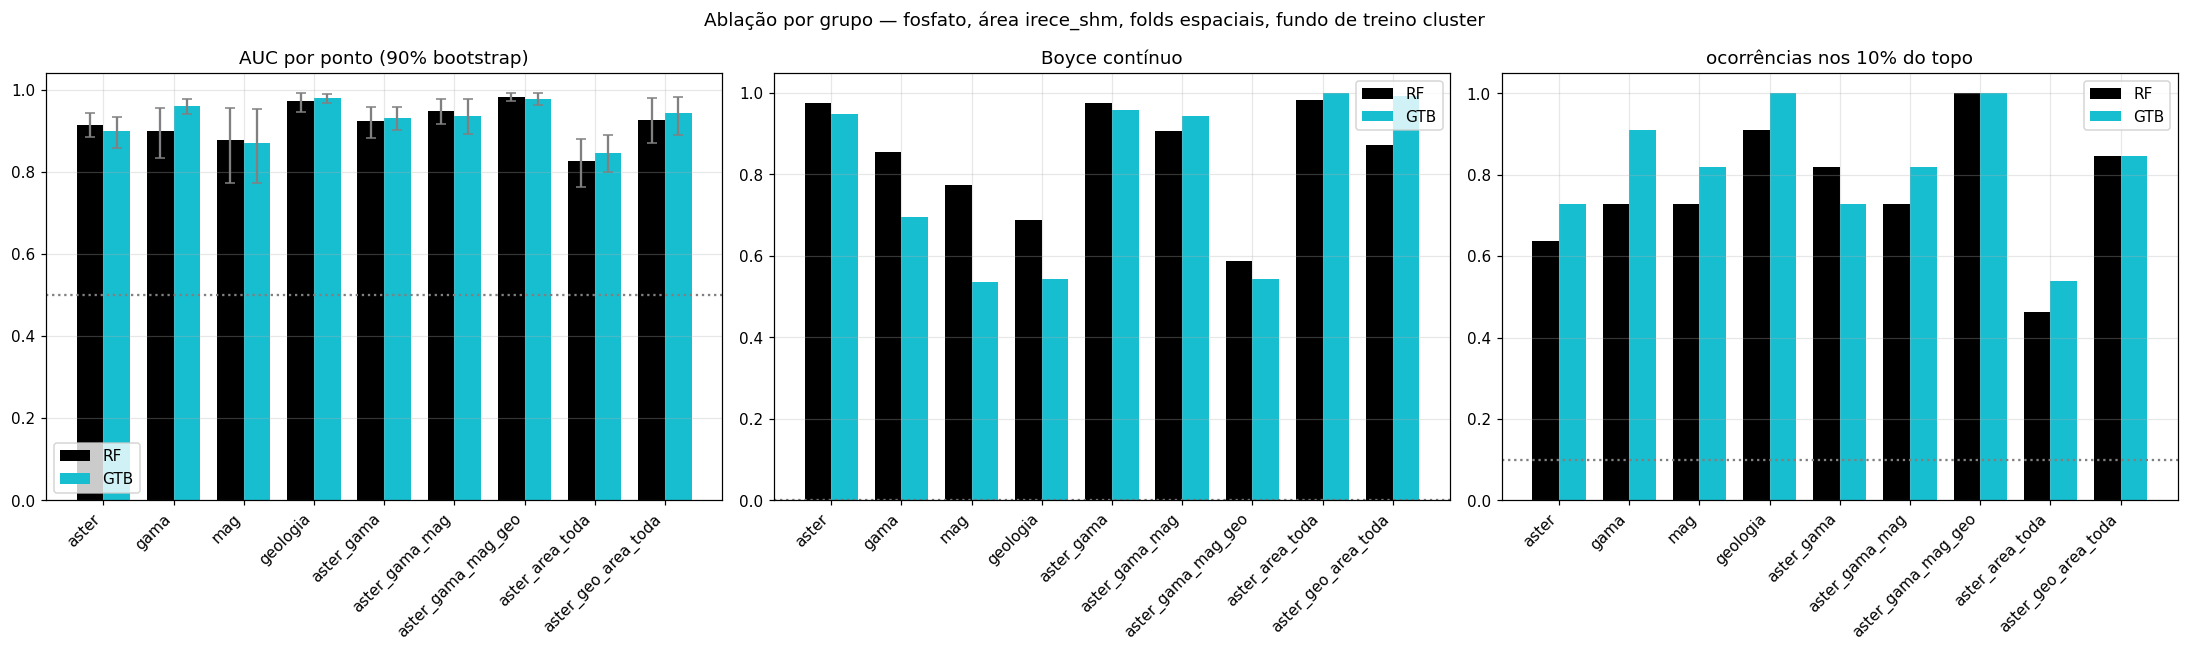

In [11]:
# [12]
CONJ = {   # nome → (variáveis, universo geo?)
    'aster':               (RED['aster'], True),
    'gama':                (RED['gama'], True),
    'mag':                 (RED['mag'], True),
    'geologia':            (RED['geologia'], True),
    'aster_gama':          (RED['aster'] + RED['gama'], True),
    'aster_gama_mag':      (RED['aster'] + RED['gama'] + RED['mag'], True),
    'aster_gama_mag_geo':  (RED['aster'] + RED['gama'] + RED['mag'] + RED['geologia'], True),
    'aster_area_toda':     (RED['aster'], False),
    'aster_geo_area_toda': (RED['aster'] + RED['geologia'], False),
}
OOF, linhas = {}, []
for nome, (feats, usa_geo) in CONJ.items():
    p, f = UNIV['geo' if usa_geo else 'toda']
    for mod, Cls in MODELOS_CLS.items():
        op, of, _ = oof(p, f, feats, Cls)
        OOF[(nome, mod)] = (op, of)
        linhas.append({'conjunto': nome, 'modelo': mod, 'variaveis': len(feats), **metricas(op, of, p)})
        print(f'{nome:20s} {mod:4s} AUC {linhas[-1]["auc_ponto"]:.3f} '
              f'[{linhas[-1]["auc_p05"]:.2f}–{linhas[-1]["auc_p95"]:.2f}]  Boyce {linhas[-1]["boyce"]:.2f}  '
              f'top10 {linhas[-1]["top10"]:.2f}')
ABL = pd.DataFrame(linhas)

fig, axs = plt.subplots(1, 3, figsize=(20, 6))
x = np.arange(len(CONJ)); w = 0.38
for k, mod in enumerate(MODELOS_CLS):
    t = ABL[ABL.modelo == mod].set_index('conjunto').loc[list(CONJ)]
    axs[0].bar(x + (k - 0.5) * w, t.auc_ponto, w, color=COR_MOD[mod], label=mod,
               yerr=[t.auc_ponto - t.auc_p05, t.auc_p95 - t.auc_ponto], capsize=3, ecolor='grey')
    axs[1].bar(x + (k - 0.5) * w, t.boyce, w, color=COR_MOD[mod], label=mod)
    axs[2].bar(x + (k - 0.5) * w, t.top10, w, color=COR_MOD[mod], label=mod)
for ax, tit, ref in zip(axs, ['AUC por ponto (90% bootstrap)', 'Boyce contínuo', 'ocorrências nos 10% do topo'],
                        [0.5, 0, 0.1]):
    ax.set_xticks(x, list(CONJ), rotation=45, ha='right'); ax.axhline(ref, c='grey', ls=':')
    ax.set_title(tit); ax.legend()
fig.suptitle(f'Ablação por grupo — fosfato, área {AREA}, folds espaciais, fundo de treino {FUNDO_MODO}'); fig.tight_layout()
salvar(fig, '12', f'ablacao_{AREA}_{FUNDO_MODO}')
ABL.pivot(index='conjunto', columns='modelo', values=['auc_ponto', 'boyce', 'top10']).loc[list(CONJ)].round(3)

`[12a]`

**Leitura da figura [12]** (rodada de 2026-10-27, fundo de treino por cluster, K = 10).
Os números mudam se o fundo ou os folds mudarem; refaça a leitura depois de rodar de novo.

| conjunto | AUC RF / GTB | Boyce RF / GTB | top10 RF / GTB | leitura |
|---|---|---|---|---|
| aster | 0,96 / 0,96 | 0,81 / 0,74 | 0,91 / 0,91 | base forte só com o espectral |
| gama | 0,92 / 0,95 | 0,89 / 0,76 | 0,73 / 0,91 | o gama sozinho já ordena bem |
| mag | 0,88 / 0,79 | 0,82 / 0,12 | 0,64 / 0,55 | o mais fraco; no GTB não ordena |
| geologia | 0,98 / 0,98 | 0,57 / 0,31 | 0,91 / 1,00 | AUC alta com Boyce baixo: copia o contorno de Nova América (p em degraus) |
| aster_gama | 0,96 / 0,97 | 0,83 / 0,80 | 0,91 / 0,91 | o gama soma pouco ao aster |
| **aster_gama_mag** | 0,98 / 0,97 | 0,78 / 0,70 | 1,00 / 1,00 | equilibrado: as três métricas boas |
| aster_gama_mag_geo | 0,99 / 0,99 | 0,49 / 0,75 | 1,00 / 1,00 | a geologia sobe a AUC 0,01 e derruba o Boyce do RF |
| aster_area_toda | 0,92 / 0,91 | 0,97 / 0,97 | 0,77 / 0,77 | outro universo (13 ocorrências, 18 425 px de fundo): não comparar direto |
| aster_geo_area_toda | 0,95 / 0,93 | 0,89 / 0,70 | 0,85 / 0,85 | idem |

Como ler cada métrica:
- **AUC por ponto**: chance de uma ocorrência ter p maior que um pixel de fundo
  sorteado. Quase tudo passa de 0,9, mas isso é otimista: as 11 ocorrências estão no
  mesmo distrito, e o modelo aprende a reconhecê-lo.
- **Boyce**: se o p funciona como escala (quanto maior o p, mais ocorrências do que o
  esperado pela área). AUC alta com Boyce baixo significa que o mapa separa em blocos,
  sem gradação útil nos valores intermediários.
- **top10**: fração das ocorrências nos 10% da área com maior p. Com 11 ocorrências,
  cada degrau vale 0,09: de 0,91 para 1,00 é uma ocorrência.

**Conclusão** (pela regra da [11], diferenças de AUC menores que ~0,05 não decidem):
- `aster_gama_mag` é o candidato: as três métricas são boas e não depende do mapa
  geológico.
- Acrescentar a geologia não compensa: ganha 0,01 de AUC e o mapa passa a repetir a
  unidade mapeada.
- A mag sozinha é fraca, mas no conjunto leva o top10 a 1,00.
- A decisão final passa pela conferência com P₂O₅ em rocha ([17]), que é dado
  independente.


`[13]`

## 5. Ranking estável

No conjunto escolhido (`CONJUNTO_SEL`; `None` = o de maior AUC por ponto média
entre RF e GTB), repete `N_REP` vezes: sorteia `FRAC_REP` das ocorrências, refaz
os folds, calcula o SHAP de cada fold com o modelo treinado sem ele e soma a
importância (|SHAP| médio). Conta em quantas repetições × modelos cada variável
fica entre as `TOP_K`. Entra quem passa de `FREQ_MIN`.

Por que não a importância Gini do RF: ela é calculada dentro da amostra e favorece
variáveis contínuas e lisas, como o gama de 500 m, que "decora" a posição de
poucos pontos. Demora: o SHAP do RF é a parte lenta (reduza `SHAP_N` ou tire o RF
de `SHAP_MODELOS` para testar).

**Regra de decisão.** Em cada repetição e modelo, as variáveis são ordenadas pelo
|SHAP| médio, somado nos folds. `freq_topo` = fração das repetições × modelos em
que a variável ficou entre as `TOP_K`. Entram as de `freq_topo` ≥ `FREQ_MIN`; se
forem menos de 3, ficam as 5 mais frequentes.

**Figura [14].** Barras = `freq_topo`, vermelho = escolhida, cinza = fora. A linha
tracejada é o `FREQ_MIN`. O número ao lado é o |SHAP| médio normalizado (soma 1):
uma variável pode ser muito importante em média mas instável (cai fora do topo
quando algumas ocorrências saem), e é exatamente isso que o critério evita.


conjunto: aster_gama_mag_geo (42 variáveis, universo geo)
repetição 1/20
repetição 2/20
repetição 3/20
repetição 4/20
repetição 5/20
repetição 6/20
repetição 7/20
repetição 8/20
repetição 9/20
repetição 10/20
repetição 11/20
repetição 12/20
repetição 13/20
repetição 14/20
repetição 15/20
repetição 16/20
repetição 17/20
repetição 18/20
repetição 19/20
repetição 20/20
SELECAO (12): ['dist_dobra_km', 'lito_nova_america', 'MAG_nT', 'eU_ppm', 'CT', 'B09', 'eTh_ppm', 'U_K', 'mag_thg', 'phosphorite_rbd', 'ferric_ox_4_3', 'mag_res']
figura → c14_ranking_estavel_irece_shm_aster_gama_mag_geo_cluster.png


,freq_topo,imp_media,freq_GTB,freq_RF
dist_dobra_km,1.000,0.298,1.00,1.00
lito_nova_america,1.000,0.205,1.00,1.00
MAG_nT,1.000,0.096,1.00,1.00
eU_ppm,1.000,0.055,1.00,1.00
CT,1.000,0.049,1.00,1.00
B09,0.975,0.033,1.00,0.95
eTh_ppm,0.950,0.032,0.90,1.00
U_K,0.950,0.024,0.90,1.00
mag_thg,0.875,0.026,0.75,1.00
phosphorite_rbd,0.775,0.012,0.90,0.65


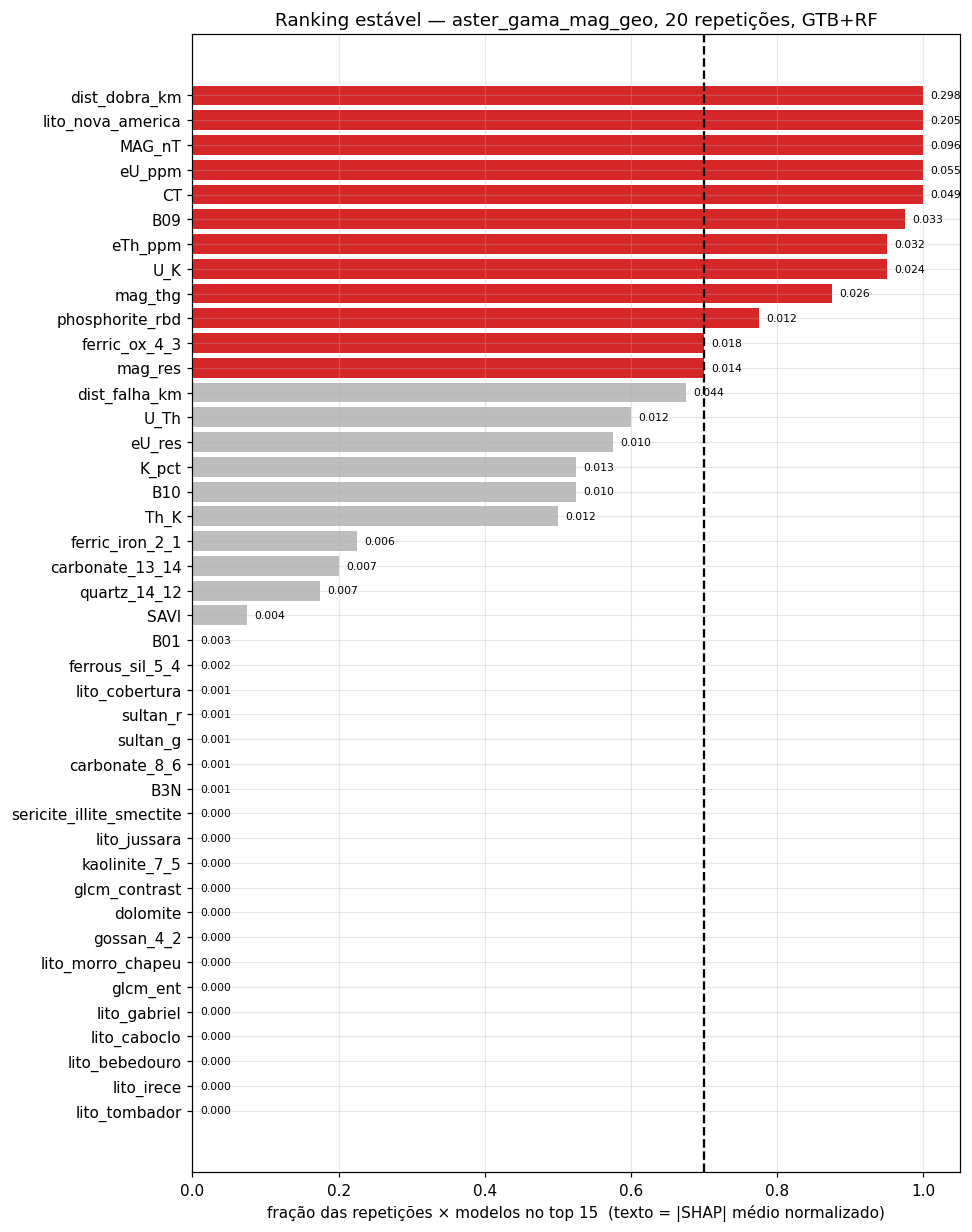

In [12]:
# [14]
import shap

CONJUNTO_SEL = None
if CONJUNTO_SEL is None:
    CONJUNTO_SEL = ABL.groupby('conjunto').auc_ponto.mean().idxmax()
feats_sel, geo_sel = CONJ[CONJUNTO_SEL]
print(f'conjunto: {CONJUNTO_SEL} ({len(feats_sel)} variáveis, universo {"geo" if geo_sel else "toda"})')

def shap_arvore(modelo, X):
    est = modelo.rf if hasattr(modelo, 'rf') else modelo.gb
    sv = shap.TreeExplainer(est).shap_values(X, check_additivity=False)
    if isinstance(sv, list):
        sv = sv[1]
    if sv.ndim == 3:
        sv = sv[..., 1]
    return sv

p0, f0 = UNIV['geo' if geo_sel else 'toda']
codigos = p0.CODIGO_OBJ.unique()
REP = []    # (repetição, modelo, importância normalizada por variável)
for rep in range(N_REP):
    escolhidos = rng.choice(codigos, max(3, int(round(FRAC_REP * len(codigos)))), replace=False)
    p = p0[p0.CODIGO_OBJ.isin(escolhidos)]
    fp, ff, _ = montar_folds(p, f0)
    for mod in SHAP_MODELOS:
        imp = np.zeros(len(feats_sel))
        for k in sorted(fp.unique()):
            p_tr = p[fp != k]
            m = MODELOS_CLS[mod]().fit(p_tr[feats_sel].values,
                                       fundo_treino(p_tr, f0[ff != k], feats_sel)[feats_sel].values)
            tp, tf = p[fp == k], f0[ff == k]
            X = pd.concat([tp.sample(min(len(tp), SHAP_N // 2), random_state=rep),
                           tf.sample(min(len(tf), SHAP_N // 2), random_state=rep)])[feats_sel].values
            imp += np.abs(shap_arvore(m, X)).mean(0)
        REP.append({'rep': rep, 'modelo': mod, **dict(zip(feats_sel, imp / imp.sum()))})
    print(f'repetição {rep + 1}/{N_REP}')
REP = pd.DataFrame(REP)

imp = REP[feats_sel]
no_topo = imp.rank(axis=1, ascending=False) <= TOP_K
ESTAB = pd.DataFrame({'freq_topo': no_topo.mean(), 'imp_media': imp.mean(),
                      **{f'freq_{m}': no_topo[REP.modelo == m].mean() for m in SHAP_MODELOS}}
                     ).sort_values(['freq_topo', 'imp_media'], ascending=False)
SELECAO = ESTAB.index[ESTAB.freq_topo >= FREQ_MIN].tolist()
if len(SELECAO) < 3:
    SELECAO = ESTAB.index[:5].tolist()
    print('poucas variáveis estáveis — ficam as 5 mais frequentes')
print(f'SELECAO ({len(SELECAO)}):', SELECAO)

fig, ax = plt.subplots(figsize=(9, max(4, 0.32 * len(feats_sel))))
e = ESTAB.iloc[::-1]
ax.barh(e.index, e.freq_topo, color=['#d62728' if v in SELECAO else '#bdbdbd' for v in e.index])
ax.axvline(FREQ_MIN, c='k', ls='--')
for i, (v, row) in enumerate(e.iterrows()):
    ax.text(row.freq_topo + 0.01, i, f'{row.imp_media:.3f}', va='center', fontsize=7)
ax.set_xlabel(f'fração das repetições × modelos no top {TOP_K}  (texto = |SHAP| médio normalizado)')
ax.set_title(f'Ranking estável — {CONJUNTO_SEL}, {N_REP} repetições, {"+".join(SHAP_MODELOS)}')
salvar(fig, '14', f'ranking_estavel_{AREA}_{CONJUNTO_SEL}_{FUNDO_MODO}')
ESTAB.round(3)

`[14a]`

**Conferência da seleção.** Refaz a validação espacial só com `SELECAO` e compara com
o conjunto de origem. A tabela tem que mostrar AUC, Boyce e top10 parecidos ou
melhores. Se caírem bem mais que ~0,05, `FREQ_MIN` ou `TOP_K` cortou demais:
aumente `TOP_K` ou baixe `FREQ_MIN` e rode [14] de novo.

In [14]:
# [15]
# a seleção não pode perder desempenho frente ao conjunto inteiro
CONJ['selecao'] = (SELECAO, geo_sel)
p, f = UNIV['geo' if geo_sel else 'toda']
for mod, Cls in MODELOS_CLS.items():
    op, of, _ = oof(p, f, SELECAO, Cls)
    OOF[('selecao', mod)] = (op, of)
    ABL = pd.concat([ABL, pd.DataFrame([{'conjunto': 'selecao', 'modelo': mod, 'variaveis': len(SELECAO),
                                         **metricas(op, of, p)}])], ignore_index=True)
ABL[ABL.conjunto.isin([CONJUNTO_SEL, 'selecao'])].set_index(['conjunto', 'modelo']).round(3)

variaveis  auc_ponto  auc_p05  auc_p95  ap_ganho  \
conjunto           modelo                                                     
aster_gama_mag_geo RF             42      0.982    0.973    0.991    51.697   
                   GTB            42      0.978    0.963    0.991    48.170   
selecao            RF             12      0.986    0.978    0.993    68.930   
                   GTB            12      0.983    0.972    0.991    68.630   

                           boyce  top10  ocorrencias  
conjunto           modelo                             
aster_gama_mag_geo RF      0.588    1.0           11  
                   GTB     0.543    1.0           11  
selecao            RF      0.462    1.0           11  
                   GTB     0.518    1.0           11

`[16]`

## 6. Conferência independente — P₂O₅ em rocha

As 78 amostras de rocha do `geoquimica_p2o5` (63 na cobertura geofísica, as usadas
quando o conjunto tem geofísica) não entram no treino. Cada uma
recebe o p fora da amostra (fold da região dela), comparado ao p fora da amostra
do fundo. Se o mapa ordena bem a área, as amostras com P₂O₅ alto caem no topo.
As amostras a menos de 2 km de uma ocorrência são mostradas à parte: elas estão na
vizinhança que o modelo aprendeu.

**Figura [17].** Um painel por modelo. Eixo x: P₂O₅ da amostra (escala log; linha
pontilhada em `LIMIAR_P2O5`). Eixo y: percentil do p da amostra no fundo (linha em
90 = topo de 10% da área). A cor é a distância à ocorrência mais próxima (amarelo =
perto, azul-escuro = 20 km ou mais).
- Bom sinal: as amostras com P₂O₅ alto (à direita da linha) ficam acima de 90, e a
  nuvem sobe da esquerda para a direita.
- Se só as amostras amarelas (perto das ocorrências) ficam no topo, o modelo
  reconhece a vizinhança, não o fosfato; olhe a linha "a ≥ 2 km" da tabela.

Na tabela: `spearman` (e `p_valor`) entre o percentil e o P₂O₅; `alto_no_top10` e
`baixo_no_top10` = fração das amostras de teor alto e baixo no topo de 10%. O
modelo serve quando `alto_no_top10` fica bem acima de `baixo_no_top10`.


figura → c17_conferencia_p2o5_irece_shm_cluster.png


,modelo,amostras,n,spearman,p_valor,n_alto,alto_no_top10,baixo_no_top10
0,RF,todas,63,0.313,0.013,4,1.0,0.271
1,RF,a ≥ 2 km,55,0.036,0.794,0,0.0,0.218
2,GTB,todas,63,0.230,0.070,4,1.0,0.305
3,GTB,a ≥ 2 km,55,-0.021,0.881,0,0.0,0.255


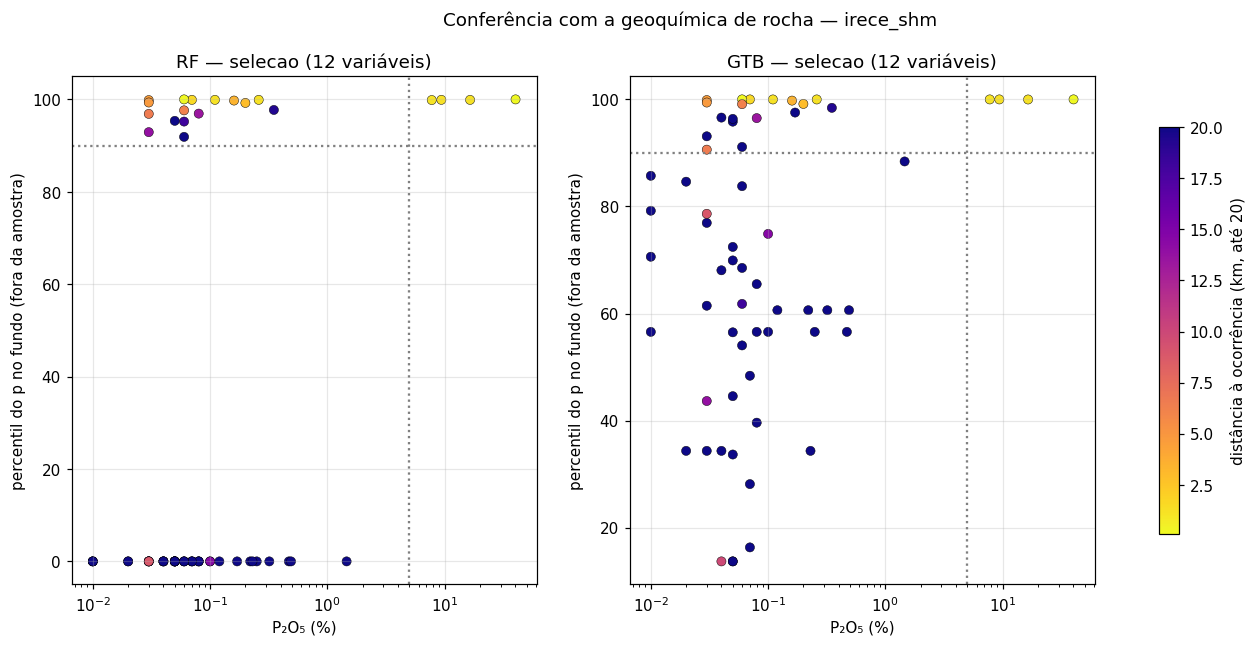

In [13]:
# [17]
geoq = GEOQ[GEOQ.tem_geofisica == 1] if geo_sel else GEOQ
lat0 = OC.lat.mean()
d = ((_km(geoq.lon, geoq.lat, lat0)[:, None] - _km(OC.lon, OC.lat, lat0)[None]) ** 2).sum(-1) ** 0.5
geoq = geoq.assign(dist_ocorrencia_km=d.min(1))
CONF = []
fig, axs = plt.subplots(1, 2, figsize=(15, 6))
for ax, (mod, Cls) in zip(axs, MODELOS_CLS.items()):
    _, of, oe = oof(p, f, SELECAO, Cls, extra=geoq)
    pct = np.searchsorted(np.sort(of.values), oe.values) / len(of) * 100
    longe = geoq.dist_ocorrencia_km.values >= 2
    alto = geoq.p2o5_pct.values >= LIMIAR_P2O5
    for nome, m in [('todas', np.ones(len(geoq), bool)), ('a ≥ 2 km', longe)]:
        rho = spearmanr(pct[m], geoq.p2o5_pct.values[m])
        CONF.append({'modelo': mod, 'amostras': nome, 'n': int(m.sum()), 'spearman': rho.statistic,
                     'p_valor': rho.pvalue, 'n_alto': int((m & alto).sum()),
                     'alto_no_top10': ((pct >= 90) & m & alto).sum() / max(1, (m & alto).sum()),
                     'baixo_no_top10': ((pct >= 90) & m & ~alto).sum() / max(1, (m & ~alto).sum())})
    sc = ax.scatter(geoq.p2o5_pct.clip(lower=0.01), pct, c=geoq.dist_ocorrencia_km.clip(upper=20), cmap='plasma_r',
                    edgecolor='k', lw=0.3)
    ax.set_xscale('log'); ax.axvline(LIMIAR_P2O5, c='grey', ls=':'); ax.axhline(90, c='grey', ls=':')
    ax.set_xlabel('P₂O₅ (%)'); ax.set_ylabel('percentil do p no fundo (fora da amostra)')
    ax.set_title(f'{mod} — selecao ({len(SELECAO)} variáveis)')
fig.colorbar(sc, ax=axs, shrink=0.8, label='distância à ocorrência (km, até 20)')
fig.suptitle(f'Conferência com a geoquímica de rocha — {AREA}')
salvar(fig, '17', f'conferencia_p2o5_{AREA}_{FUNDO_MODO}')
CONF = pd.DataFrame(CONF)
CONF.round(3)

`[17a]`

**O que é o p de uma amostra.** O modelo (RF ou GTB) recebe os valores das variáveis
de um pixel e devolve um número entre 0 e 1, o **p**: a nota de favorabilidade
daquele lugar. p perto de 1 = o pixel se parece com os pixels das ocorrências; perto
de 0 = se parece com o fundo.

Para cada amostra de rocha:
1. pega o pixel de 30 m onde ela foi coletada e lê as variáveis da seleção nesse pixel
   (as mesmas 7 do modelo), como faria com qualquer pixel do mapa;
2. o modelo que dá a nota é o do **fold da região da amostra**, treinado sem as
   ocorrências e sem o fundo daquele bloco de 10 km (por isso "fora da amostra");
3. o resultado é o p da amostra. O teor de P₂O₅ **não entra** no cálculo: o modelo
   não sabe o teor, só vê ASTER, geofísica e geologia.

**Por que o percentil e não o p direto.** O valor do p depende da proporção entre
presença e fundo no treino (com fundo 3 × presença, o neutro fica em ≈ 0,25), então
"p = 0,4" não diz muito sozinho. O percentil compara a amostra com o resto da área: o
p da amostra é posto na fila dos p de todos os pixels de fundo (também fora da
amostra). Percentil 95 = a amostra tem p maior que 95% da área. Percentil 90 é o
limite dos 10% mais favoráveis, a área que se mandaria para o campo.

**Como ler a figura [17].** Cada ponto é uma amostra de rocha (63 na cobertura
geofísica). Eixo x = teor de P₂O₅ (log), linha vertical em 5% (à direita, as amostras
ricas). Eixo y = percentil do p, linha horizontal em 90 (acima, o topo de 10% da
área). Cor = distância à ocorrência mais próxima: amarelo = perto, azul-escuro =
20 km ou mais.

Um bom mapa mostraria as amostras ricas no alto, a nuvem subindo da esquerda para a
direita, e amostras ricas longe das ocorrências (azuis) também no alto.

**O que a figura mostra** (rodada de 2026-10-27, seleção de 7 variáveis do conjunto
`aster_gama_mag_geo`):
1. as 4 amostras ricas ficam no alto (no GTB, uma em 86), mas todas são amarelas, a
   menos de 2 km de uma ocorrência: o modelo já aprendeu aquela vizinhança, e acertar
   ali não prova nada;
2. muitas rochas pobres (< 1%) também caem no topo: 35–39% delas, contra 10% esperados
   ao acaso. A área de p alto inclui muita rocha sem fosfato;
3. as amostras azuis (longe) se espalham de 0 a 100 sem padrão; no RF há uma fileira
   em 0 (p igual a zero);
4. na tabela, o Spearman com todas as amostras é ≈ 0,27 (p-valor < 0,05), mas com as
   amostras a ≥ 2 km some (0,06–0,11, p-valor > 0,4), e não há nenhuma amostra rica
   longe das ocorrências.

**Conclusão.** O modelo separa "perto do distrito" de "longe do distrito", mas não
separa teor alto de teor baixo. Com estes dados, o teste não confirma o mapa fora do
distrito, porque não existe amostra rica longe das ocorrências. (O "p-valor" da
tabela é o do teste de Spearman, não tem relação com o p do modelo.)

`[18]`

## 7. Variáveis salvas para o export

`models/variaveis_AR_<area>.json` leva todos os conjuntos (o `exportar_favorabilidade_AR.py`
oferece todos no menu), com `selecao` como recomendado. Métricas e frequências vão
para CSV na mesma pasta.

Com `FUNDO_MODO = 'cluster'`, o fundo de treino do export vem do
`models/cluster_fundo_AR_<area>.json` gravado na [10e]: o GEE refaz a atribuição de
cada pixel de fundo ao cluster mais próximo e treina só com os clusters de treino. Os
conjuntos com geofísica ganham `_fcl` no nome da imagem; os da área toda usam o fundo
aleatório.

In [15]:
# [19]
saida = {
    'area': AREA, 'conjuntos': {k: v[0] for k, v in CONJ.items()},
    'usa_geofisica': {k: bool(v[1]) for k, v in CONJ.items()},
    'recomendado': 'selecao', 'conjunto_base_selecao': CONJUNTO_SEL, 'n_por_ponto': N_POR_PONTO,
    'fundo_modo': FUNDO_MODO,
    'parametros': {'R_MAX': R_MAX, 'N_FOLDS': N_FOLDS, 'BLOCO_KM': BLOCO_KM, 'N_REP': N_REP, 'FRAC_REP': FRAC_REP,
                   'TOP_K': TOP_K, 'FREQ_MIN': FREQ_MIN, 'SHAP_MODELOS': SHAP_MODELOS,
                   'K_FUNDO': K_FUNDO, 'FRAC_MIN_FUNDO': FRAC_MIN_FUNDO,
                   'VARS_CLUSTER': VARS_CLUSTER},
}
arq = MODELS / f'variaveis_AR_{AREA}.json'
arq.write_text(json.dumps(saida, indent=1, ensure_ascii=False))
ABL.to_csv(MODELS / f'selecao_AR_{AREA}_{FUNDO_MODO}_ablacao.csv', index=False)
ESTAB.to_csv(MODELS / f'selecao_AR_{AREA}_{FUNDO_MODO}_ranking_estavel.csv')
CONF.to_csv(MODELS / f'selecao_AR_{AREA}_{FUNDO_MODO}_conferencia_p2o5.csv', index=False)
print(f'→ {arq}\n  selecao = {SELECAO}')

→ /home/superuser/Dados/proj/prosprectra/modelagem_prospectra_mine/src/modeling/models/variaveis_AR_irece_shm.json
  selecao = ['dist_dobra_km', 'lito_nova_america', 'MAG_nT', 'eU_ppm', 'CT', 'B09', 'eTh_ppm', 'U_K', 'mag_thg', 'phosphorite_rbd', 'ferric_ox_4_3', 'mag_res']
